# Data & Apprentissage, M2CHPS

## Assignments - Part 1

**Instructor:** [Argyris Kalogeratos](http://kalogeratos.com) (contact: argyris.kalogeratos@ens-paris-saclay.fr).   
**Syllabus:** [http://nvayatis.perso.math.cnrs.fr/CHPScourse.html](http://nvayatis.perso.math.cnrs.fr/CHPScourse.html)

The most updated version of this file can be found at the instructor's webpage:  
[http://kalogeratos.com/MyCourses/DML-M2HPC/Assignments1.ipynb](http://kalogeratos.com/files/MyCourses/DML-M2HPC/Assignments1.ipynb).


# Worked solution

Run the cells from top to bottom. All datasets are generated here or included in scikit-learn, so no data download is needed. The original questions are kept above the answers. The code uses fixed seeds.

Required packages: `numpy scipy pandas matplotlib scikit-learn`.
If needed, install them in the notebook kernel with `%pip install numpy scipy pandas matplotlib scikit-learn`.
The last exercise takes longer because it runs the full parameter grid.


## 0. Before you start

* Work on the assignment either alone or in a team of two (pair). For those that will pick working in a team, the point is not to split the work, but to collaborate! 
* Prepare **a single Jupyter notebook** in a report-like format for all the exercises. Use this notebook as a starting point and place your answers just below each exercise. Describe properly what you do in each step of your solution, followed by your well-commented code implementation that can automatically produce figures and numerical results. Results should also be well-commented and discussed. Your comments can be either in English or in French.
* Mathematical expressions need to be writen in tex directly in the notebook (not handwritten!). 
* Important: send your notebook that includes all your work and any additional files you used (e.g. datasets) by email, with a title ``M2CHPS <year> - <Surname1> & <Surname2>``. The title of the notebook should have the surnames of the students. The body of the email should also mention the students' names and how they split the work; if you face difficulties in clarifying this with your classmate, please write separate emails with your views. 
* Always use references for things you reuse (e.g. websites, forums, books, published papers, etc.)
* Do not copy-paste from the internet recipes that do the asked thing (or what is most usually observed: to use something relevant but not exactly what is asked). You need to understand what you use (sources should be properly referenced), adapt it to what each exercise asks for, and comment clearly the results. Poorly commented and explained pieces of work/code will not be taken seriously into account. 
* Copying from one another is not acceptable. We are strict with that: cheating in even one exercise will incur **a zero to all projects** (not just one assignment). Your work will be cross-checked against all the other submissions.
* **Use of LLMs** should be clearly disclosed (where and how they were used): add at the end of your notebook a short cell titled *"Use of LLMs"* that states which tool(s) you used, for which parts, and what you changed in their output. A missing or misleading disclosure is treated as in the previous point. Using such tools to understand a method, debug a problem in the code, or ask for a chunk of python API for trivial operations (e.g. plotting, loading data, etc) is normal. Results that are uncommented or poorly commented will earn little or no credit. However, the grade is on your own experimental work and your understanding of it: an answer that you cannot explain, or that is not supported by your own runs, numbers and figures, counts for nothing.
* The assignments will be examined orally at the end of the semester. Each group of students should be able to explain in about 10 mins all what they did, and answer short questions.
* **Deadline: midnight 18/10.**
* **Late submissions:** the maximum possible grade is penalized by 5%/day. E.g. when delivering on time the best grade is 20/20, late submission by one day gets at best 19/20, for two days late of delay 18/20...


In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
import joblib

from scipy.spatial.distance import cdist
from scipy.stats import norm
from sklearn.datasets import make_regression, load_breast_cancer
from sklearn.linear_model import LinearRegression, RANSACRegressor, LogisticRegression
from sklearn.svm import OneClassSVM
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from threadpoolctl import threadpool_limits
from IPython.display import display

# These small experiments are faster with one BLAS thread.
thread_limit = threadpool_limits(limits=1)
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.precision', 4)
# Save generated tables and the fitted model relative to the notebook working directory.
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
print('NumPy:', np.__version__, '| SciPy:', scipy.__version__, '| scikit-learn:', sklearn.__version__)

NumPy: 2.2.6 | SciPy: 1.15.3 | scikit-learn: 1.7.2


## Exercise 1 - [25%]
Read about the iterative [RANdom SAmple Consensus (RANSAC)](https://en.wikipedia.org/wiki/Random_sample_consensus) method for robust linear regression. Consult also the material of the Lab and the documentation of scikit learn.

**a)** Implement from scratch your own code for the RANSAC algorithm. You can still use as a building block the native linear regression of scikit learn in your implementation. Then, compare it with the simple linear regression and the built-in RANSAC implementation of scikit learn.

a1) Apply your solution to the dataset of the example given in [Lab 1](http://kalogeratos.com/MyCourses/DML-M2HPC/Lab1.ipynb) to see that it  matches the behavior of the already coded method of scikit learn. Create plots including the linear models found by the typical linear regressor, the scikit RANSAC, and your version(s).

a2) Apply your method to the following cases:
* Use only the part of the inliers that comes from the inclined linear model (about 1000 points). Add extra $p$% of noisy points (where $p$ can be 5%, 10%, 20%, 30%) by picking random elements of the data and perturbing them "sufficiently" with a Gaussian noise so that they get dislocated far from the rest of the data on both sides.
* Do as before, but constrain the perturbation to be only positive (all noisy points will be above the inline data).
* Do as before, but the perturbed data will not be randomly selected, but rather correspond to the $p$% of the points with lower $y$ coordinate (the points at the lower left part of the plot).

What differences do you observe among these cases. Report with illustrative results and comments. You can test additional cases using the same data generation code, after changing some of the parameters (e.g. the number of outliers and their distance to the inliers).

**b)** The original RANSAC uses inlying data points as votes for candidate models. An alternative is to use the opposite approach: i.e. to use the models to vote for the most inlying points. Implement this variation that operates as follows:
- Each time you subsample from the data, build a linear model, all inliers get a vote +1.
- After having built the predefined number of models, use the top q% (e.g. 75%) voted points and build the final linear model using only those points.

Use the previous dataset or/and other variations you may generate to demonstrate differences in performance, and discuss the results.

**c)** As discussed in the class, the logic behind the RANSAC could actually be seen as a more general tool than just performing regression. More specifically, it can be seen as a way to perform various kinds of *robust estimation*. 

<img src="./cloud-of-points-outliers.png" alt="Original point-cloud illustration" style="width: 500px;"/>

c1) Assume for example the problem where we have a point-cloud of data and we want to estimate their "center", as a group representative, but in a robust way. The figure above illustrates an example where the input data contains $100$ inliers and $10$ outliers, which however you don't know a priori. Here, the inliers come from a Gaussian distribution with $\mu = (0,0)$ and $\sigma = 0.83$, while the outliers come from a Gaussian dislocated at $\mu = (5,5)$ and $\sigma = 1.5$. You can get the [.mat data file](http://kalogeratos.com/files/MyCourses/DML-M2HPC/cloud-of-points-data.mat) with this example and/or write your own code to generate it. 

How would you design a solution to this problem that adopts the RANSAC principle so that for this kind of data input we can compute a representative as close as possible to the mean of the inliers? Implement your solution as a self-contained module, e.g. a function ``robust_representative(S)`` that takes a set of datapoints $S$ and returns a representative of it, as we will reuse it in what follows.

c2) Extend this approach to the clustering of the data in a given number of $k$ clusters, by considering a centroid-based clustering method (e.g. $k$-means) as the internal model learner: at each iteration, the representative of each cluster should be computed by calling the module of (c1), instead of taking the plain mean of the cluster. Note that your implementation should remain agnostic to how the representative is computed, i.e. one should be able to plug in a different estimator without changing the clustering code. Provide an implementation and demonstrate some example(s).

c3) Write an abstract pseudocode that expresses the generalization of RANSAC in arbitrary statistical estimation or learning problems.


### 1a. RANSAC

**Question**

**a)** Implement from scratch your own code for the RANSAC algorithm. You can still use as a building block the native linear regression of scikit learn in your implementation. Then, compare it with the simple linear regression and the built-in RANSAC implementation of scikit learn.

a1) Apply your solution to the dataset of the example given in [Lab 1](http://kalogeratos.com/MyCourses/DML-M2HPC/Lab1.ipynb) to see that it  matches the behavior of the already coded method of scikit learn. Create plots including the linear models found by the typical linear regressor, the scikit RANSAC, and your version(s).

**Answer**

Run 500 random trials. In each trial, draw two distinct points and take the line through them as a candidate; skip the trial if their x coordinates are almost equal (absolute difference below `1e-12`). Compute the vertical residuals of all points relative to the candidate. Points with absolute residuals at most 25 are its inliers and form its consensus set. This implementation chooses 25 as 2.5 times the inlier noise standard deviation of 10 in the Lab 1 data. Compare candidates by inlier count; break ties by the smaller mean squared residual over their inliers. Finally, fit a least-squares line to all inliers of the winning candidate.

Two points are the smallest sample that determines a line, and the smaller the sample, the more likely it is to contain only inliers. The candidate depends on the noise in those two points; refitting on the whole consensus set reduces this dependence. The custom parameters `threshold` and `trials` correspond to sklearn’s `residual_threshold` and `max_trials`. Too small a threshold rejects genuine inliers; too large a threshold admits outliers. The custom implementation always runs all `trials` (500 here), whereas the sklearn RANSAC used for comparison sets `stop_probability=0.999` and may stop earlier based on the inlier ratio found so far.



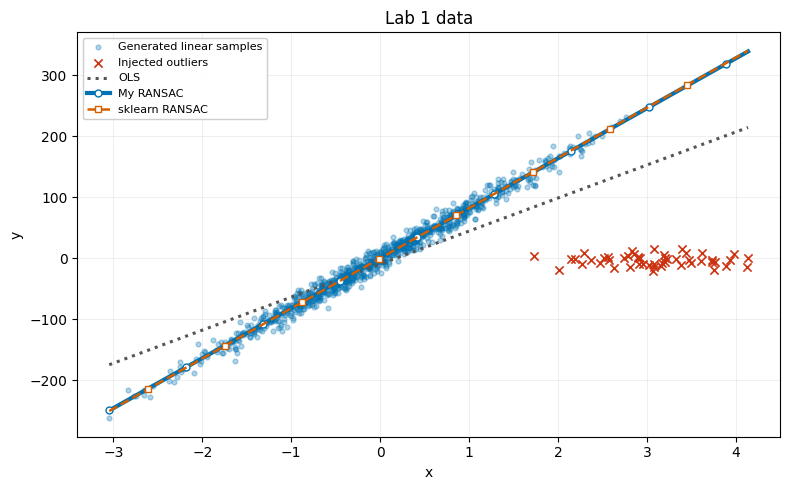

True slope: 82.1903908407869


,Method,Slope,Intercept
0,OLS,54.1724,-9.3665
1,My RANSAC,81.9647,0.2794
2,sklearn RANSAC,82.2502,0.2931


In [2]:
def ransac_line(X, y, threshold=25, trials=500, seed=0):
    # X has shape (n, 1); y has shape (n,). The threshold is a vertical distance in y units.
    rng = np.random.default_rng(seed)
    x = X[:, 0]
    best_inliers = None
    best_count = 0
    best_error = np.inf

    # Try many two-point lines; one uncontaminated pair may reveal the main trend.
    for trial in range(trials):
        i, j = rng.choice(len(y), 2, replace=False)
        # Skip pairs with almost equal x coordinates to avoid dividing by a near-zero difference.
        if abs(x[j] - x[i]) < 1e-12:
            continue
        slope = (y[j] - y[i]) / (x[j] - x[i])
        intercept = y[i] - slope * x[i]
        residual = np.abs(y - (slope * x + intercept))
        inliers = residual <= threshold
        count = inliers.sum()
        error = np.mean(residual[inliers] ** 2)
        # Prefer more inliers; if counts tie, prefer smaller mean squared inlier residuals.
        if count > best_count or (count == best_count and error < best_error):
            best_inliers = inliers
            best_count = count
            best_error = error

    if best_inliers is None:
        raise ValueError('No valid pair of points.')
    # Refit on the whole winning consensus, rather than only the sampled pair.
    model = LinearRegression().fit(X[best_inliers], y[best_inliers])
    return model


# The same data generation and corruption as Lab 1.
clean_X, clean_y, true_slope = make_regression(
    n_samples=1000, n_features=1, noise=10, coef=True, random_state=0)
# Keep the original noisy linear data for later experiments; corrupt copies here.
lab_X = clean_X.copy()
lab_y = clean_y.copy()
lab_rng = np.random.RandomState(0)
# Replace 50 existing points: the total stays 1000, unlike the additions in 1a2.
lab_X[:50] = 3 + 0.5 * lab_rng.normal(size=(50, 1))
lab_y[:50] = -3 + 10 * lab_rng.normal(size=50)

lab_models = {
    'OLS': LinearRegression().fit(lab_X, lab_y),
    'My RANSAC': ransac_line(lab_X, lab_y),
    'sklearn RANSAC': RANSACRegressor(
        residual_threshold=25, min_samples=2, max_trials=500,
        stop_probability=0.999, random_state=0).fit(lab_X, lab_y)
}
# Use a common, ordered x grid to draw all fitted lines.
line_X = np.linspace(lab_X.min(), lab_X.max(), 200).reshape(-1, 1)
# Point shapes show generation labels, not algorithm-predicted inlier labels.
regression_styles = {
    'OLS': dict(color='#555555', linestyle=':', linewidth=2.2, zorder=3),
    'My RANSAC': dict(color='#0072B2', linestyle='-', linewidth=3.0,
                      marker='o', markevery=(0, 24), markersize=5,
                      markerfacecolor='white', zorder=4),
    'sklearn RANSAC': dict(color='#D55E00', linestyle='--', linewidth=1.8,
                           marker='s', markevery=(12, 24), markersize=5,
                           markerfacecolor='white', zorder=5)
}
plt.figure(figsize=(8, 5))
plt.scatter(lab_X[50:], lab_y[50:], s=12, marker='o', alpha=0.3,
            color='#0072B2', label='Generated linear samples', zorder=1)
plt.scatter(lab_X[:50], lab_y[:50], s=35, marker='x', linewidths=1.2,
            color='#CC3311', label='Injected outliers', zorder=2)
lab_rows = []
for name, model in lab_models.items():
    plt.plot(line_X, model.predict(line_X), label=name, **regression_styles[name])
    # sklearn stores its final fitted linear model in estimator_.
    fitted_line = model.estimator_ if name == 'sklearn RANSAC' else model
    lab_rows.append([name, fitted_line.coef_[0], fitted_line.intercept_])
plt.xlabel('x')
plt.ylabel('y')
plt.title('Lab 1 data')
plt.legend(fontsize=8, framealpha=0.95)
plt.tight_layout()
plt.show()
print('True slope:', float(true_slope))
display(pd.DataFrame(lab_rows, columns=['Method', 'Slope', 'Intercept']))

The fitted slopes are 81.96 for the custom RANSAC and 82.25 for sklearn, close to the true slope 82.19. OLS gives 54.17. Thus both RANSAC implementations recover the main trend in this dataset, while OLS is strongly affected by the displaced points. Their coefficients need not coincide because the random samples and stopping rules differ.


**Question**

a2) Apply your method to the following cases:
* Use only the part of the inliers that comes from the inclined linear model (about 1000 points). Add extra $p$% of noisy points (where $p$ can be 5%, 10%, 20%, 30%) by picking random elements of the data and perturbing them "sufficiently" with a Gaussian noise so that they get dislocated far from the rest of the data on both sides.
* Do as before, but constrain the perturbation to be only positive (all noisy points will be above the inline data).
* Do as before, but the perturbed data will not be randomly selected, but rather correspond to the $p$% of the points with lower $y$ coordinate (the points at the lower left part of the plot).

What differences do you observe among these cases. Report with illustrative results and comments. You can test additional cases using the same data generation code, after changing some of the parameters (e.g. the number of outliers and their distance to the inliers).

**Answer**

Start from the 1000 uncorrupted linear samples and append perturbed copies of p% of them. Thus p=30% adds 300 points, giving 1300 in total. Perturb only y: use both signs, positive perturbations at randomly selected points, or positive perturbations at the lowest y values. Resample Gaussian draws with absolute value below 60, then take absolute values for the positive cases; these are truncated perturbations.

For each setting, compare all three methods on the same data and repeat with five seeds. Evaluate RMSE against the known noise-free line at the original x values, so the score measures recovery of the relation rather than fit to contaminated responses.


Method                        My RANSAC      OLS  sklearn RANSAC
Case                 Added %                                    
Both sides           5           0.3844   1.5860          0.9168
                     10          0.4000   2.5819          0.9293
                     20          0.4096   3.1378          0.6832
                     30          0.4082   2.5533          0.5846
Lower-left, positive 5           0.3844  14.3428          0.9168
                     10          0.4000  22.4449          0.9293
                     20          0.4096  33.9225          0.6832
                     30          0.4082  41.6998          0.5846
Positive             5           0.3844   8.0979          0.9168
                     10          0.4000  15.0777          0.9293
                     20          0.4096  27.1894          0.6832
                     30          0.4082  37.4391          0.5846

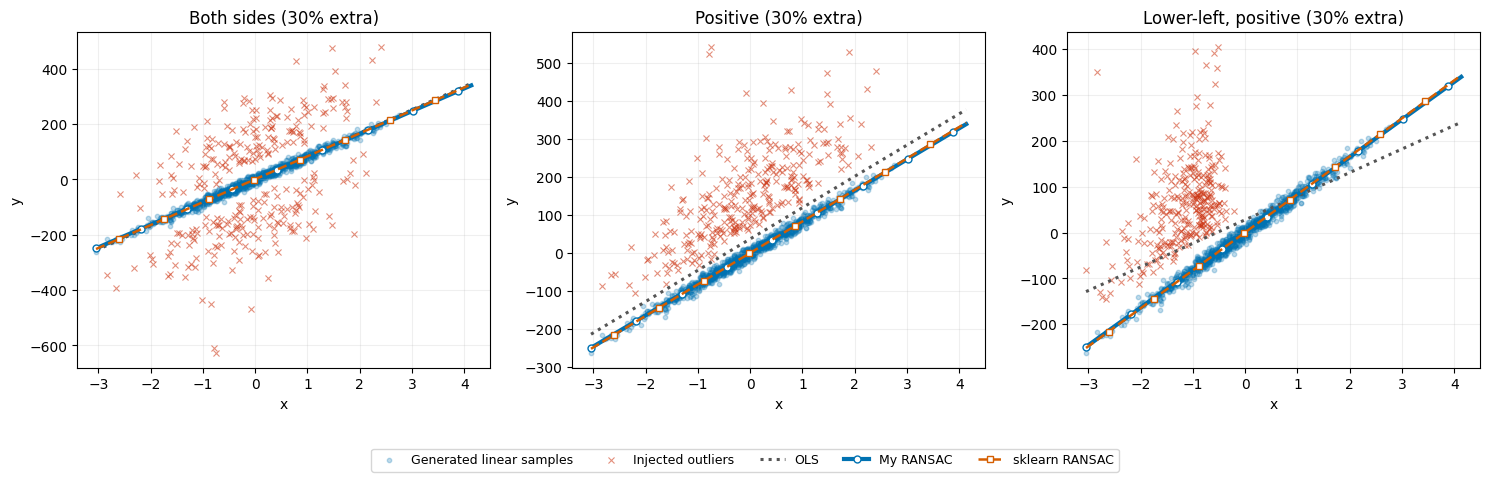

In [3]:
def add_outliers(mode, percent, seed):
    rng = np.random.default_rng(seed)
    # percent is relative to the original 1000 points: 30 means 300 added points.
    count = int(len(clean_y) * percent / 100)
    # The lower-left case selects the smallest y values; other cases sample randomly.
    if mode == 'Lower-left, positive':
        indices = np.argsort(clean_y)[:count]
    else:
        indices = rng.choice(len(clean_y), count, replace=False)
    noise = rng.normal(0, 150, count)
    too_small = np.abs(noise) < 60
    # Resample small perturbations so added copies are well separated from their source points.
    while too_small.any():
        noise[too_small] = rng.normal(0, 150, too_small.sum())
        too_small = np.abs(noise) < 60
    # Take absolute values for the two upward-only cases; keep both signs otherwise.
    if mode != 'Both sides':
        noise = np.abs(noise)
    # Append perturbed copies; the original points remain in the dataset.
    X = np.vstack([clean_X, clean_X[indices]])
    y = np.concatenate([clean_y, clean_y[indices] + noise])
    return X, y


modes = ['Both sides', 'Positive', 'Lower-left, positive']
percentages = [5, 10, 20, 30]
regression_rows = []
example_models = {}
for mode in modes:
    for percent in percentages:
        # Repeat each setting with five seeds and use the same data for all three methods.
        for seed in range(5):
            X, y = add_outliers(mode, percent, seed)
            models = {
                'OLS': LinearRegression().fit(X, y),
                'My RANSAC': ransac_line(X, y, seed=seed),
                'sklearn RANSAC': RANSACRegressor(
                    residual_threshold=25, min_samples=2, max_trials=500,
                    stop_probability=0.999, random_state=seed).fit(X, y)
            }
            for name, model in models.items():
                # Compare with the known noise-free line, not with the contaminated observations.
                rmse = np.sqrt(np.mean((model.predict(clean_X) - true_slope * clean_X[:, 0]) ** 2))
                regression_rows.append([mode, percent, seed, name, rmse])
            # Keep one representative fitted example per case for the plots below.
            if percent == 30 and seed == 0:
                example_models[mode] = models

regression_results = pd.DataFrame(regression_rows, columns=['Case', 'Added %', 'Seed', 'Method', 'RMSE'])
# pivot_table averages the five seed results for each case, percentage and method.
display(regression_results.pivot_table(index=['Case', 'Added %'], columns='Method', values='RMSE'))

# Point shapes show generation labels, not algorithm-predicted inlier labels.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, mode in zip(axes, modes):
    X, y = add_outliers(mode, 30, 0)
    ax.scatter(X[:len(clean_y)], y[:len(clean_y)], s=10, marker='o',
               alpha=0.25, color='#0072B2', label='Generated linear samples', zorder=1)
    ax.scatter(X[len(clean_y):], y[len(clean_y):], s=19, marker='x',
               alpha=0.55, linewidths=0.8, color='#CC3311',
               label='Injected outliers', zorder=2)
    for name, model in example_models[mode].items():
        ax.plot(line_X, model.predict(line_X), label=name, **regression_styles[name])
    ax.set(title=mode + ' (30% extra)', xlabel='x', ylabel='y')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5, fontsize=9)
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

The table reports mean RMSE across five seeds. At 30% extra points, OLS has RMSE 2.5533 for two-sided perturbations, 37.4391 for random positive perturbations, and 41.6998 for positive perturbations at the lowest y values. Symmetric perturbations partly cancel; positive perturbations shift the fit upward, and concentrating them at the lower-left also changes its slope. The location and direction of contamination therefore matter alongside its amount.

The custom RANSAC has RMSE about 0.38–0.41 across these settings; at 30% extra points it is 0.4082 in all three cases to the displayed precision. The perturbations were deliberately kept away from zero, which helps separate them from the main consensus. This result concerns clearly separated contamination; it does not establish the same robustness when outliers overlap the line.


### 1b. Voting for points

**Question**

**b)** The original RANSAC uses inlying data points as votes for candidate models. An alternative is to use the opposite approach: i.e. to use the models to vote for the most inlying points. Implement this variation that operates as follows:
- Each time you subsample from the data, build a linear model, all inliers get a vote +1.
- After having built the predefined number of models, use the top q% (e.g. 75%) voted points and build the final linear model using only those points.

Use the previous dataset or/and other variations you may generate to demonstrate differences in performance, and discuss the results.

**Answer**

Every random line gives one vote to each of its inliers. Only the top 75% of points are used for the final fit. Ties are resolved by original row order.


In [4]:
def voting_line(X, y, fraction=0.75, threshold=25, trials=500, seed=0):
    rng = np.random.default_rng(seed)
    x = X[:, 0]
    # Each entry counts how many candidate lines accept that observation as an inlier.
    votes = np.zeros(len(y), dtype=int)
    for trial in range(trials):
        i, j = rng.choice(len(y), 2, replace=False)
        if abs(x[j] - x[i]) < 1e-12:
            continue
        slope = (y[j] - y[i]) / (x[j] - x[i])
        intercept = y[i] - slope * x[i]
        # Adding a Boolean array adds 1 for accepted points and 0 for the others.
        votes += np.abs(y - (slope * x + intercept)) <= threshold
    # Keep the requested fraction, rounded up, with at least two points for a line.
    count = max(2, int(np.ceil(fraction * len(y))))
    # Sort by decreasing votes; stable sorting preserves row order when votes tie.
    selected = np.argsort(-votes, kind='stable')[:count]
    return LinearRegression().fit(X[selected], y[selected])


# Reuse the same cases and seeds as 1a2 so the RMSE comparison is matched.
vote_rows = []
for mode in modes:
    for percent in percentages:
        for seed in range(5):
            X, y = add_outliers(mode, percent, seed)
            model = voting_line(X, y, seed=seed)
            rmse = np.sqrt(np.mean((model.predict(clean_X) - true_slope * clean_X[:, 0]) ** 2))
            vote_rows.append([mode, percent, seed, 'Point voting', rmse])

vote_results = pd.DataFrame(vote_rows, columns=regression_results.columns)
all_regression = pd.concat([regression_results, vote_results], ignore_index=True)
display(all_regression.pivot_table(index=['Case', 'Added %'], columns='Method', values='RMSE'))

Method                        My RANSAC      OLS  Point voting  sklearn RANSAC
Case                 Added %                                                  
Both sides           5           0.3844   1.5860        0.3905          0.9168
                     10          0.4000   2.5819        0.3368          0.9293
                     20          0.4096   3.1378        0.5395          0.6832
                     30          0.4082   2.5533        0.4380          0.5846
Lower-left, positive 5           0.3844  14.3428        0.3972          0.9168
                     10          0.4000  22.4449        0.3691          0.9293
                     20          0.4096  33.9225        0.6823          0.6832
                     30          0.4082  41.6998        0.4672          0.5846
Positive             5           0.3844   8.0979        0.3932          0.9168
                     10          0.4000  15.0777        0.3402          0.9293
                     20          0.4096  27.1894        0.5969          0.6832
                     30          0.4082  37.4391        0.4365          0.5846

Point voting combines evidence from many models instead of choosing a single consensus. It can also discard useful inliers when q is too small, or retain outliers when q is too large. Here even the largest contamination leaves about 77% clean points, so q=75% is a reasonable fixed choice. It is not guaranteed to beat ordinary RANSAC: for the lower-left case with 30% extra points, its RMSE is 0.467, versus 0.408 for my RANSAC.


### 1c1. A robust representative

**Question**

c1) Assume for example the problem where we have a point-cloud of data and we want to estimate their "center", as a group representative, but in a robust way. The figure above illustrates an example where the input data contains $100$ inliers and $10$ outliers, which however you don't know a priori. Here, the inliers come from a Gaussian distribution with $\mu = (0,0)$ and $\sigma = 0.83$, while the outliers come from a Gaussian dislocated at $\mu = (5,5)$ and $\sigma = 1.5$. You can get the [.mat data file](http://kalogeratos.com/files/MyCourses/DML-M2HPC/cloud-of-points-data.mat) with this example and/or write your own code to generate it. 

How would you design a solution to this problem that adopts the RANSAC principle so that for this kind of data input we can compute a representative as close as possible to the mean of the inliers? Implement your solution as a self-contained module, e.g. a function ``robust_representative(S)`` that takes a set of datapoints $S$ and returns a representative of it, as we will reuse it in what follows.

**Answer**

Draw three points, use their mean as a candidate centre, and count points within radius 2.5. Keep the largest consensus and return its mean. This assumes one dominant compact group. The radius is in data units and must change if the scale changes. Known inlier labels are used only to evaluate the answer.

The consensus set now uses Euclidean distance to a centre. A small radius can discard useful points; a large radius can merge the main cloud with outliers.


Inlier mean [-0.194 -0.209] error to inlier mean = 0.0
All-data mean [0.246 0.28 ] error to inlier mean = 0.6578
RANSAC [-0.194 -0.209] error to inlier mean = 0.0


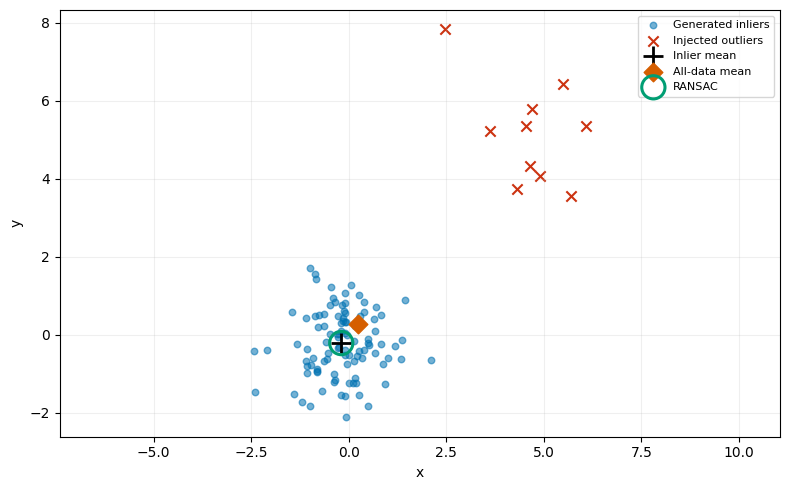

In [5]:
def robust_representative(S, radius=2.5, trials=100, seed=0):
    # S contains one point per row; the returned vector has one coordinate per feature.
    rng = np.random.default_rng(seed)
    best_inliers = None
    best_count = 0
    best_error = np.inf
    for trial in range(trials):
        # Average a small random subset to propose a centre; small clusters use all available points.
        indices = rng.choice(len(S), min(3, len(S)), replace=False)
        centre = S[indices].mean(axis=0)
        distances = np.linalg.norm(S - centre, axis=1)
        # Here consensus uses Euclidean distance to a centre, not a regression residual.
        inliers = distances <= radius
        count = inliers.sum()
        if count == 0:
            continue
        error = np.mean(distances[inliers] ** 2)
        # Keep the largest compact group; use its spread to break equal-count ties.
        if count > best_count or (count == best_count and error < best_error):
            best_inliers = inliers
            best_count = count
            best_error = error
    # Use coordinate-wise medians only if no candidate obtained any support.
    if best_inliers is None:
        return np.median(S, axis=0)
    return S[best_inliers].mean(axis=0)


rng = np.random.default_rng(10)
cloud_inliers = rng.normal(0, 0.83, (100, 2))
cloud_outliers = rng.normal(5, 1.5, (10, 2))
cloud = np.vstack([cloud_inliers, cloud_outliers])
# Known inliers define an evaluation reference only; the estimator receives the full cloud.
inlier_mean = cloud_inliers.mean(axis=0)
ransac_centre = robust_representative(cloud)
plain_centre = cloud.mean(axis=0)
# Point shapes show generation labels, not algorithm-predicted inlier labels.
centre_styles = {
    'Inlier mean': dict(marker='+', s=220, color='black', linewidths=2.0, zorder=5),
    'All-data mean': dict(marker='D', s=90, color='#D55E00', zorder=4),
    'RANSAC': dict(marker='o', s=280, facecolors='none', edgecolors='#009E73',
                   linewidths=2.2, zorder=6)
}
plt.figure(figsize=(8, 5))
plt.scatter(*cloud_inliers.T, s=22, marker='o', alpha=0.55,
            color='#0072B2', label='Generated inliers')
plt.scatter(*cloud_outliers.T, s=55, marker='x', linewidths=1.5,
            color='#CC3311', label='Injected outliers')
for name, centre in [('Inlier mean', inlier_mean), ('All-data mean', plain_centre), ('RANSAC', ransac_centre)]:
    plt.scatter(*centre, label=name, **centre_styles[name])
    print(name, np.round(centre, 3), 'error to inlier mean =', round(np.linalg.norm(centre - inlier_mean), 4))
plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

The ordinary mean is 0.658 away from the inlier sample mean; RANSAC matches it to the displayed precision. The reference is the mean of these 100 inliers, `(-0.194, -0.209)`, rather than the population centre `(0, 0)`. A displayed zero does not imply exact recovery of the population centre or the same result on other samples.


### 1c2. Clustering

**Question**

c2) Extend this approach to the clustering of the data in a given number of $k$ clusters, by considering a centroid-based clustering method (e.g. $k$-means) as the internal model learner: at each iteration, the representative of each cluster should be computed by calling the module of (c1), instead of taking the plain mean of the cluster. Note that your implementation should remain agnostic to how the representative is computed, i.e. one should be able to plug in a different estimator without changing the clustering code. Provide an implementation and demonstrate some example(s).

**Answer**

The assignment step uses the nearest centre. The update step calls the supplied `representative` function. For initialization, k centres are drawn at random, with a fixed seed, from the 75% of points closest to the coordinate-wise median. This reduces the chance of starting at a distant outlier. All compared methods start from the same centres. The iteration limit is needed because a robust update need not decrease the usual k-means objective.


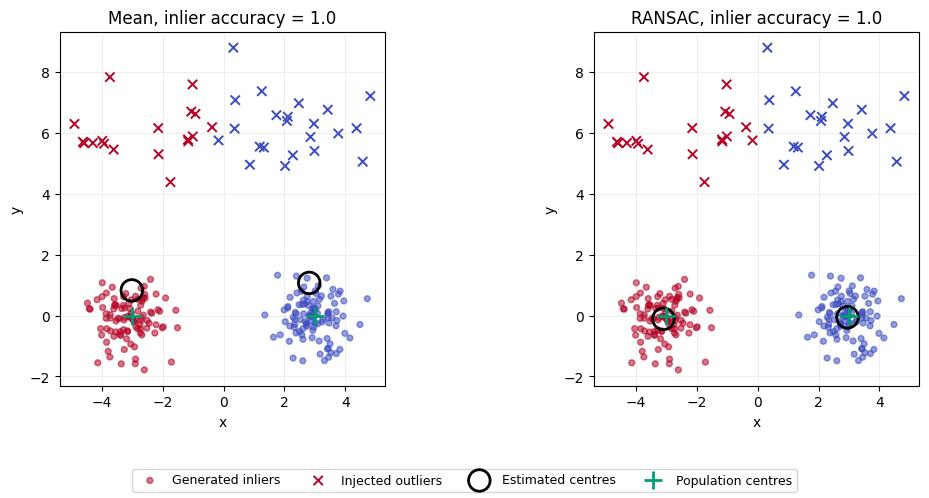

In [6]:
def cluster_data(X, k, representative, seed=0, max_iter=30):
    # Draw k initial centres at random from the 75% of points closest to the coordinate-wise median.
    middle = np.median(X, axis=0)
    order = np.argsort(np.linalg.norm(X - middle, axis=1))
    candidates = order[:max(k, int(0.75 * len(X)))]
    rng = np.random.default_rng(seed)
    centres = X[rng.choice(candidates, k, replace=False)]
    for iteration in range(max_iter):
        # Assign each point to its nearest current centre; cluster labels are column indices.
        labels = cdist(X, centres).argmin(axis=1)
        # An empty cluster keeps its old centre; nonempty clusters call the supplied estimator.
        new_centres = centres.copy()
        for group in range(k):
            members = X[labels == group]
            if len(members) > 0:
                new_centres[group] = representative(members)
        # Stop when centres stop moving; max_iter also bounds nonconverging robust updates.
        if np.allclose(new_centres, centres, atol=1e-5, rtol=0):
            centres = new_centres
            break
        centres = new_centres
    labels = cdist(X, centres).argmin(axis=1)
    return centres, labels


def mean_representative(S):
    return S.mean(axis=0)


def inlier_accuracy(true_labels, labels):
    # Cluster IDs are arbitrary: score both ways of matching two clusters to two classes.
    accuracy = np.mean(labels == true_labels)
    return max(accuracy, 1 - accuracy)


rng = np.random.default_rng(20)
true_centres = np.array([[-3., 0.], [3., 0.]])
cluster_inliers = np.vstack([rng.normal(true_centres[0], 0.6, (100, 2)),
                             rng.normal(true_centres[1], 0.6, (100, 2))])
cluster_outliers = np.column_stack([rng.uniform(-5, 5, 40), rng.normal(6, 1, 40)])
cluster_X = np.vstack([cluster_inliers, cluster_outliers])
# Only the first 200 points have true cluster labels; outliers are excluded from the accuracy.
true_labels = np.repeat([0, 1], 100)
# Point shapes show generation labels, not algorithm-predicted inlier labels.
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, name, estimator in zip(axes, ['Mean', 'RANSAC'], [mean_representative, robust_representative]):
    centres, labels = cluster_data(cluster_X, 2, estimator)
    ax.scatter(*cluster_X[:200].T, c=labels[:200], s=18, marker='o',
               alpha=0.55, cmap='coolwarm', vmin=0, vmax=1, label='Generated inliers')
    ax.scatter(*cluster_X[200:].T, c=labels[200:], s=45, marker='x',
               linewidths=1.4, cmap='coolwarm', vmin=0, vmax=1, label='Injected outliers')
    ax.scatter(*centres.T, edgecolors='black', facecolors='none', marker='o',
               linewidths=2, s=240, label='Estimated centres', zorder=4)
    ax.scatter(*true_centres.T, c='#009E73', marker='+', s=180,
               linewidths=2, label='Population centres', zorder=5)
    ax.set(xlabel='x', ylabel='y')
    ax.set_title(name + ', inlier accuracy = ' + str(round(inlier_accuracy(true_labels, labels[:200]), 3)))
    ax.set_aspect('equal')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=9)
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

Both methods obtain inlier accuracy 1, so all 200 inliers are partitioned correctly in this example. However, the ordinary means are still pulled towards the upper outliers. Accuracy measures the partition, not the centre coordinates, so correct groups and displaced centres can coexist. Outliers still receive cluster labels here; the robust update changes which points determine each centre.


### 1c3. General form

**Question**

c3) Write an abstract pseudocode that expresses the generalization of RANSAC in arbitrary statistical estimation or learning problems.

**Answer**

```text
best_support = empty
repeat T times:
    sample a small subset
    fit a candidate estimator on this subset
    evaluate the loss of every observation under this candidate
    support = observations with loss <= threshold
    keep the candidate with the largest support (break ties using loss)
refit the estimator on the best support
return the refitted estimator
```

The model and the loss depend on the task: vertical residual for a line, distance for a centre, or another suitable statistical loss. The method needs enough uncontaminated subsets and a meaningful threshold.


## Exercise 2 - [15%]

In the previous exercise the representative of a set of datapoints was estimated following the RANSAC principle. Here we look at alternative ways to perform the same *robust estimation*, and we compare them.

**a)** Investigate the use of a *one-class SVM* (see also Lab 3) as the building block of such an estimator. Design and implement it, explain the role of the parameters of the model (in particular of the one that controls the fraction of the data that the model is allowed to leave out), and compare the representative you obtain with the one of Exercise 1 (c1) and with the plain mean of all the data.

**b)** Implement the following simple deterministic estimator of the representative $r$ of a set $S$, called *synthetic prototype*: 

Step 1: $r \leftarrow \text{medoid}(S)$

Step 2: $r \leftarrow \text{mean}$ of the $x$% of the datapoints that are closest to $r$

Step 3: $r \leftarrow \text{mean}$ of the $y$% of the datapoints that are closest to $r$

... and so on, with $x < y < ... < z$, i.e. each step averages over a growing neighborhood around the representative computed at the previous step.

In practice two steps are usually enough (e.g. $x=10$%, $y=80$%). Study the sensitivity of the result to the percentages and to the number of steps. This estimator computes a trimmed mean, in the sense that it excludes certain objects in the set; it has been proposed as cluster prototypes in: Kalogeratos et al., Document clustering using synthetic cluster prototypes, Data & Knowledge Engineering, 2011 ([see Algorithm 2](https://kalogeratos.com/files/MyPapers/Document-clustering-using-synthetic-cluster-prototypes-DKE2011-recompiled.pdf); the distance/similarity measure is of user's choice).

**c)** Plug the two estimators of (a) and (b) into the clustering procedure of Exercise 1 (c2), and compare the three variants (RANSAC-based, one-class-SVM-based, growing-neighborhood) along the following axes:

* the quality of the representatives when the proportion of the outliers increases and when the outliers move further away from the inliers;
* what each parameter of the estimators actually controls (a fraction of the data, a distance threshold, ...), and how easy it is to set it in practice;
* the computational cost, and whether the result is deterministic or not.

Report with illustrative results and comments.


### 2a. One-class SVM

**Question**

**a)** Investigate the use of a *one-class SVM* (see also Lab 3) as the building block of such an estimator. Design and implement it, explain the role of the parameters of the model (in particular of the one that controls the fraction of the data that the model is allowed to leave out), and compare the representative you obtain with the one of Exercise 1 (c1) and with the plain mean of all the data.

**Answer**

Fit an RBF one-class SVM and average the points it accepts. `nu` is an upper bound on the fraction of training errors and a lower bound on the fraction of support vectors, subject to numerical tolerance; it is not the exact outlier fraction. `gamma` controls the spatial scale: a larger value gives more local boundaries. The features here have the same units, so no rescaling is used.

See the [OneClassSVM documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.OneClassSVM.html).



In [7]:
def svm_representative(S, nu=0.2, gamma=0.5):
    # Fit an RBF acceptance region, then estimate the centre from accepted points.
    model = OneClassSVM(nu=nu, gamma=gamma).fit(S)
    # OneClassSVM returns +1 for accepted points and -1 for rejected points.
    accepted = model.predict(S) == 1
    # If no point is accepted, return the point with the highest decision score.
    if not accepted.any():
        return S[model.decision_function(S).argmax()]
    return S[accepted].mean(axis=0)


centre_rows = []
for name, centre in [('Mean', plain_centre), ('RANSAC', ransac_centre), ('One-class SVM', svm_representative(cloud))]:
    centre_rows.append([name, centre[0], centre[1], np.linalg.norm(centre - inlier_mean)])
display(pd.DataFrame(centre_rows, columns=['Method', 'x', 'y', 'Error to inlier mean']))

# Vary nu and gamma separately; record actual rejection rates as well as centre errors.
svm_rows = []
for nu in [0.1, 0.2, 0.3]:
    for gamma in [0.1, 0.5, 1.0]:
        model = OneClassSVM(nu=nu, gamma=gamma).fit(cloud)
        accepted = model.predict(cloud) == 1
        centre = svm_representative(cloud, nu, gamma)
        svm_rows.append([nu, gamma, 1 - accepted.mean(), np.linalg.norm(centre - inlier_mean)])
display(pd.DataFrame(svm_rows, columns=['nu', 'gamma', 'Rejected fraction', 'Centre error']))

,Method,x,y,Error to inlier mean
0,Mean,0.2460,0.2804,0.6578
1,RANSAC,-0.1941,-0.2085,0.0000
2,One-class SVM,0.0008,-0.0041,0.2825


,nu,gamma,Rejected fraction,Centre error
0,0.1,0.1,0.1000,0.4099
1,0.1,0.5,0.0727,0.4421
2,0.1,1.0,0.1364,0.5681
3,0.2,0.1,0.2000,0.0362
4,0.2,0.5,0.1818,0.2825
5,0.2,1.0,0.2455,0.0346
6,0.3,0.1,0.3000,0.0182
7,0.3,0.5,0.3091,0.0359
8,0.3,1.0,0.3091,0.0533


On this cloud, the errors to the inlier mean are 0.658 for the plain mean, 0.000 for RANSAC, and 0.283 for the SVM with nu=0.2 and gamma=0.5. Changing gamma to 0.1 reduces the SVM error to 0.036. A one-class SVM can retain part of a small, separated outlier group. Its accepted region need not correspond to the single main cloud. Therefore a suitable nu alone does not guarantee an accurate representative. The measured rejected fraction can also slightly exceed nu because points numerically close to the boundary are classified by the sign of their score.


### 2b. Synthetic prototype

**Question**

**b)** Implement the following simple deterministic estimator of the representative $r$ of a set $S$, called *synthetic prototype*: 

Step 1: $r \leftarrow \text{medoid}(S)$

Step 2: $r \leftarrow \text{mean}$ of the $x$% of the datapoints that are closest to $r$

Step 3: $r \leftarrow \text{mean}$ of the $y$% of the datapoints that are closest to $r$

... and so on, with $x < y < ... < z$, i.e. each step averages over a growing neighborhood around the representative computed at the previous step.

In practice two steps are usually enough (e.g. $x=10$%, $y=80$%). Study the sensitivity of the result to the percentages and to the number of steps. This estimator computes a trimmed mean, in the sense that it excludes certain objects in the set; it has been proposed as cluster prototypes in: Kalogeratos et al., Document clustering using synthetic cluster prototypes, Data & Knowledge Engineering, 2011 ([see Algorithm 2](https://kalogeratos.com/files/MyPapers/Document-clustering-using-synthetic-cluster-prototypes-DKE2011-recompiled.pdf); the distance/similarity measure is of user's choice).

**Answer**

Initialize with the medoid, the observed point with the smallest total Euclidean distance to the other points. At each averaging step, select the specified fraction of nearest points from the full original set around the current centre, then update their mean. A small first neighbourhood limits contamination; later expansion includes more observations. Here “two steps” means two averaging steps after initialization.


In [8]:
def synthetic_representative(S, fractions=(0.1, 0.8)):
    # The medoid minimizes total distance to all observations; it must be an observed point.
    distances = cdist(S, S)
    centre = S[distances.sum(axis=1).argmin()]
    # At every step, select neighbours afresh from S around the updated centre.
    for fraction in fractions:
        order = np.argsort(np.linalg.norm(S - centre, axis=1), kind='stable')
        # Round the retained count up and keep at least one observation.
        count = max(1, int(np.ceil(fraction * len(S))))
        centre = S[order[:count]].mean(axis=0)
    return centre


# First vary the two retained fractions, then compare one-step and three-step schedules.
prototype_rows = []
for first in [0.05, 0.1, 0.2]:
    for last in [0.6, 0.8, 0.95]:
        fractions = (first, last)
        centre = synthetic_representative(cloud, fractions)
        prototype_rows.append([str(fractions), np.linalg.norm(centre - inlier_mean)])
for fractions in [(0.8,), (0.1, 0.4, 0.8)]:
    centre = synthetic_representative(cloud, fractions)
    prototype_rows.append([str(fractions), np.linalg.norm(centre - inlier_mean)])
display(pd.DataFrame(prototype_rows, columns=['Averaging fractions', 'Centre error']))

,Averaging fractions,Centre error
0,"(0.05, 0.6)",0.2229
1,"(0.05, 0.8)",0.1034
2,"(0.05, 0.95)",0.3110
3,"(0.1, 0.6)",0.2814
4,"(0.1, 0.8)",0.1034
5,"(0.1, 0.95)",0.3110
6,"(0.2, 0.6)",0.2124
7,"(0.2, 0.8)",0.0909
8,"(0.2, 0.95)",0.3110
9,"(0.8,)",0.0909


The (0.1, 0.8) schedule gives centre error 0.103. A single (0.8,) step gives 0.091, so the extra step does not improve this sample. Raising the final fraction to 0.95 increases the error to 0.311: retaining more points can bring contamination back into the average. The final fraction therefore trades use of inliers against exclusion of outliers.

For a fixed input order and tie rule, this estimator is deterministic. Its explicit pairwise distance matrix requires $O(m^2d)$ time and $O(m^2)$ memory for m points in d dimensions.


### 2c. Comparison inside clustering

**Question**

**c)** Plug the two estimators of (a) and (b) into the clustering procedure of Exercise 1 (c2), and compare the three variants (RANSAC-based, one-class-SVM-based, growing-neighborhood) along the following axes:

* the quality of the representatives when the proportion of the outliers increases and when the outliers move further away from the inliers;
* what each parameter of the estimators actually controls (a fraction of the data, a distance threshold, ...), and how easy it is to set it in practice;
* the computational cost, and whether the result is deterministic or not.

Report with illustrative results and comments.

**Answer**

Use two Gaussian clusters, with 100 inliers each and standard deviation 0.6. Add outliers around a shifted copy of each cluster, with standard deviation 0.8 and a positive vertical shift. The outlier fraction below is the fraction of the final dataset, up to rounding. Compare four fractions and four distances, using ten seeds each.

Cluster IDs are arbitrary, and two clusters can be matched to the two classes in only two ways. Centre error is the smaller mean distance over the two pairings; inlier accuracy is the higher accuracy over the two matchings and uses the 200 inliers only. The timing includes the whole clustering call. The same inliers and standardized outlier draws are reused across contamination settings for each seed.


,Centre error,Inlier accuracy,Time (ms)
Method,,,
Mean,1.4339,0.9467,0.1955
One-class SVM,1.0362,0.9594,2.5515
RANSAC,0.4325,0.9782,9.8360
Synthetic,0.6408,0.9656,0.6010


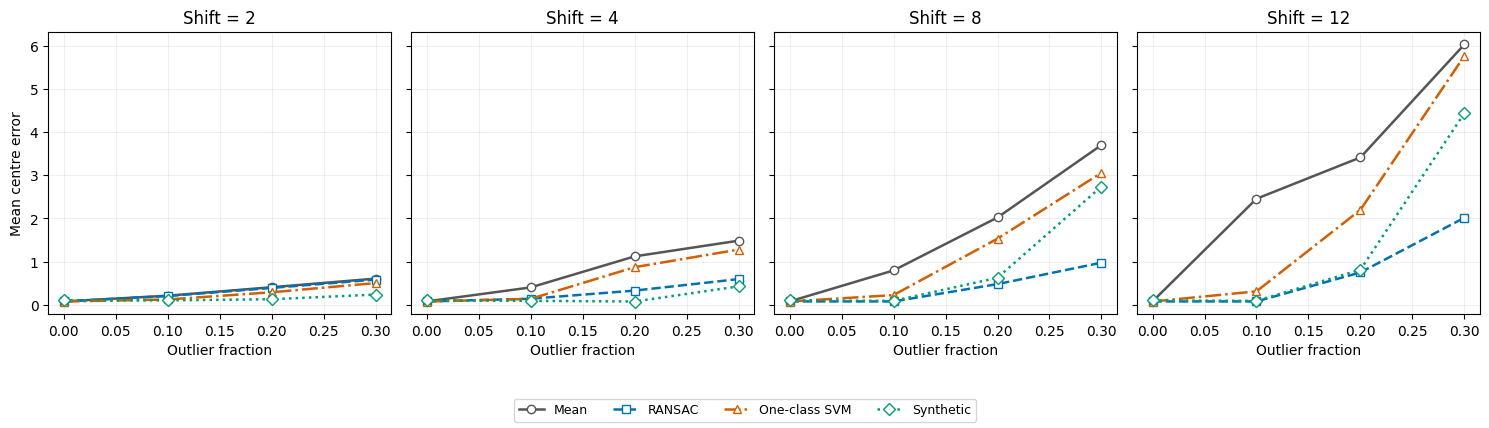

Centre error                                 Inlier accuracy  \
Method           Mean One-class SVM  RANSAC Synthetic            Mean   
Distance                                                                
2              0.6058        0.5026  0.5829    0.2365            1.00   
4              1.4835        1.2773  0.5941    0.4254            0.95   
8              3.6977        3.0551  0.9747    2.7375            0.80   
12             6.0259        5.7598  2.0149    4.4367            0.70   

                                         
Method   One-class SVM RANSAC Synthetic  
Distance                                 
2                 1.00  1.000    1.0000  
4                 0.95  1.000    1.0000  
8                 0.85  0.901    0.8000  
12                0.70  0.850    0.7495

In [9]:
estimators = {'Mean': mean_representative, 'RANSAC': robust_representative,
              'One-class SVM': svm_representative, 'Synthetic': synthetic_representative}
clustering_rows = []
for fraction in [0, 0.1, 0.2, 0.3]:
    # Solve fraction = outliers / (200 + outliers); this fraction refers to the final dataset.
    outlier_count = int(round(200 * fraction / (1 - fraction)))
    for distance in [2, 4, 8, 12]:
        for seed in range(10):
            # Reset by seed so contamination settings share inliers and overlapping outlier draws.
            rng = np.random.default_rng(100 + seed)
            inliers = np.vstack([rng.normal(true_centres[0], 0.6, (100, 2)),
                                  rng.normal(true_centres[1], 0.6, (100, 2))])
            # Alternate outlier origins between the two clusters, then shift them vertically.
            origins = true_centres[np.arange(outlier_count) % 2]
            outliers = origins + [0, distance] + rng.normal(0, 0.8, (outlier_count, 2))
            X = np.vstack([inliers, outliers])
            for name, estimator in estimators.items():
                # Time the entire clustering call, including initialization and centre updates.
                start = time.perf_counter()
                centres, labels = cluster_data(X, 2, estimator, seed=seed)
                elapsed = 1000 * (time.perf_counter() - start)
                distances = cdist(centres, true_centres)
                # Cluster IDs are arbitrary; two clusters allow only two pairings, so keep the closer one.
                error = min((distances[0, 0] + distances[1, 1]) / 2,
                            (distances[0, 1] + distances[1, 0]) / 2)
                # Evaluate the partition on inliers only, separately from the centre-position error.
                accuracy = inlier_accuracy(true_labels, labels[:200])
                clustering_rows.append([fraction, distance, seed, name, error, accuracy, elapsed])

clustering_results = pd.DataFrame(clustering_rows, columns=[
    'Outlier fraction', 'Distance', 'Seed', 'Method', 'Centre error', 'Inlier accuracy', 'Time (ms)'])
# These averages combine all tested fractions, distances and seeds.
display(clustering_results.groupby('Method')[['Centre error', 'Inlier accuracy', 'Time (ms)']].mean())
clustering_styles = {
    'Mean': dict(color='#555555', marker='o', linestyle='-'),
    'RANSAC': dict(color='#0072B2', marker='s', linestyle='--'),
    'One-class SVM': dict(color='#D55E00', marker='^', linestyle='-.'),
    'Synthetic': dict(color='#009E73', marker='D', linestyle=':')
}
fig, axes = plt.subplots(1, 4, figsize=(15, 4.3), sharey=True)
for ax, distance in zip(axes, [2, 4, 8, 12]):
    selected = clustering_results[clustering_results['Distance'] == distance]
    for name in estimators:
        curve = selected[selected['Method'] == name].groupby('Outlier fraction')['Centre error'].mean()
        ax.plot(curve.index, curve.values, label=name, linewidth=1.8,
                markerfacecolor='white', **clustering_styles[name])
    ax.set(title='Shift = ' + str(distance), xlabel='Outlier fraction')
axes[0].set_ylabel('Mean centre error')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=9)
plt.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()
display(clustering_results[clustering_results['Outlier fraction'] == 0.3].pivot_table(
    index='Distance', columns='Method', values=['Centre error', 'Inlier accuracy']))

At 30% contamination, the ranking changes with the outlier distance. At shift 2, the synthetic prototype has centre error 0.24, below RANSAC's 0.58. At shift 12, the errors are 6.03 for the mean, 5.76 for SVM, 2.01 for RANSAC and 4.44 for the synthetic prototype. RANSAC gives the smallest centre error there, but its inlier accuracy is only 0.85. Improving the centre estimate does not ensure that the partition is correct.

The settings are held fixed: radius 2.5 for RANSAC, `nu=0.2, gamma=0.5` for SVM, and fractions `(0.1, 0.8)` for the synthetic prototype. RANSAC needs a distance scale and a trial budget; SVM needs both rejection and kernel-scale settings; the prototype specifies retained fractions directly. Retaining 80% cannot exclude all outliers when contamination reaches 30%. These comparisons evaluate the chosen settings, not separately tuned optima.

RANSAC scans the data for every random trial. The synthetic prototype constructs a full distance matrix, while SVM fitting cost depends on the data. In the saved averages, their clustering times are about 9.84, 0.60 and 2.55 ms, respectively, versus 0.20 ms for the mean. These timings apply to the present small datasets. The prototype and SVM representatives are deterministic for fixed inputs; RANSAC and all clustering initializations use fixed random seeds.


## Exercise 3 - [15%]

In Section 2.5 of the book "[The Elements of Statistical Learning: Data Mining, Inference, and Prediction](https://web.stanford.edu/~hastie/ElemStatLearn//printings/ESLII_print12_toc.pdf)", by T. Hastie, R. Tibshirani, and J. Friedman, there is a mention about the effects of the *curse of dimensionality*. Read the section and implement the code to reproduce and verify all the experiments shown in the Figures 2.6, 2.7, 2.8, and 2.9.


### 3. Figures 2.6–2.9

**Question**

In Section 2.5 of the book "[The Elements of Statistical Learning: Data Mining, Inference, and Prediction](https://web.stanford.edu/~hastie/ElemStatLearn//printings/ESLII_print12_toc.pdf)", by T. Hastie, R. Tibshirani, and J. Friedman, there is a mention about the effects of the *curse of dimensionality*. Read the section and implement the code to reproduce and verify all the experiments shown in the Figures 2.6, 2.7, 2.8, and 2.9.

**Answer**

Use the setups in *The Elements of Statistical Learning*, Section 2.5, printed pages 22–27. These are new Monte Carlo runs, so the plots need not match the book point for point.

**Figure 2.6.** A cube of side length e in p dimensions has volume $e^p$. To cover a fraction r of a unit cube, $e=r^{1/p}$. The left panel shows the two-dimensional version. The simulation checks the volume relation on 100,000 uniform points.


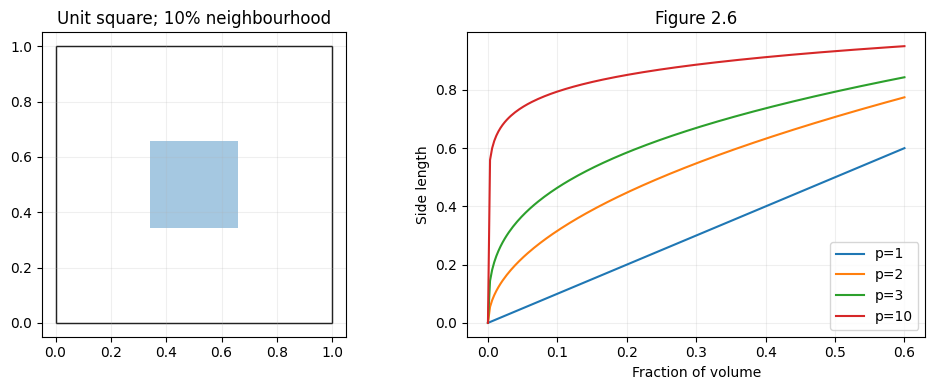

,Dimension,Target fraction,Side length,Observed fraction
0,1,0.01,0.0100,0.0098
1,1,0.10,0.1000,0.1003
2,2,0.01,0.1000,0.0098
3,2,0.10,0.3162,0.0994
4,3,0.01,0.2154,0.0101
5,3,0.10,0.4642,0.1002
6,10,0.01,0.6310,0.0100
7,10,0.10,0.7943,0.1007


In [10]:
# Draw the 2D illustration on the left and the volume-to-side-length curves on the right.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].add_patch(plt.Rectangle((0, 0), 1, 1, fill=False))
side = np.sqrt(0.1)
axes[0].add_patch(plt.Rectangle(((1 - side) / 2, (1 - side) / 2), side, side, alpha=0.4))
axes[0].set(xlim=(-0.05, 1.05), ylim=(-0.05, 1.05), title='Unit square; 10% neighbourhood')
axes[0].set_aspect('equal')
fractions = np.linspace(0, 0.6, 200)
volume_rows = []
rng = np.random.default_rng(30)
for dimension in [1, 2, 3, 10]:
    axes[1].plot(fractions, fractions ** (1 / dimension), label='p=' + str(dimension))
    # Monte Carlo check: the fraction of uniform points inside should approximate the volume.
    points = rng.uniform(0, 1, (100000, dimension))
    for fraction in [0.01, 0.1]:
        side = fraction ** (1 / dimension)
        # A point is inside only if every coordinate lies within the centred interval.
        inside = (np.abs(points - 0.5) <= side / 2).all(axis=1)
        volume_rows.append([dimension, fraction, side, inside.mean()])
axes[1].set(xlabel='Fraction of volume', ylabel='Side length', title='Figure 2.6')
axes[1].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame(volume_rows, columns=['Dimension', 'Target fraction', 'Side length', 'Observed fraction']))

In ten dimensions, capturing 10% of the volume requires about 80% of each coordinate range. A neighbourhood containing enough points is therefore no longer very local.



**Question**

In Section 2.5 of the book "[The Elements of Statistical Learning: Data Mining, Inference, and Prediction](https://web.stanford.edu/~hastie/ElemStatLearn//printings/ESLII_print12_toc.pdf)", by T. Hastie, R. Tibshirani, and J. Friedman, there is a mention about the effects of the *curse of dimensionality*. Read the section and implement the code to reproduce and verify all the experiments shown in the Figures 2.6, 2.7, 2.8, and 2.9.

This part addresses Figures 2.7 and 2.8.

**Answer**

**Figures 2.7 and 2.8.** For each dimension $p=1,\ldots,10$, generate 1000 training points uniformly in $[-1,1]^p$. Predict at the origin using its nearest neighbour. Repeat 2000 times. There is no observation noise.

The targets are $f_1(x)=\exp(-8\|x\|^2)$ and $f_2(x)=\frac12(x_1+1)^3$, with $f_1(0)=1$ and $f_2(0)=0.5$. Regenerate the whole training set on every repetition and save its prediction at the same origin. Compute MSE, squared bias and variance across these 2000 predictions, not across the 1000 responses within one training set. The Monte Carlo identity MSE = squared bias + variance uses variance with `ddof=0`.

The lecture uses $h^*$ for the true regression function and $\widehat h_n$ for the sample-based predictor; $\mathbb E_n$ and $\mathbb V_n$ average over training samples. Exercise 3 follows the assigned book's notation $f$ for the target. Even without observation noise, regenerating the training set changes the nearest neighbour and hence the prediction. This is the source of variance here.



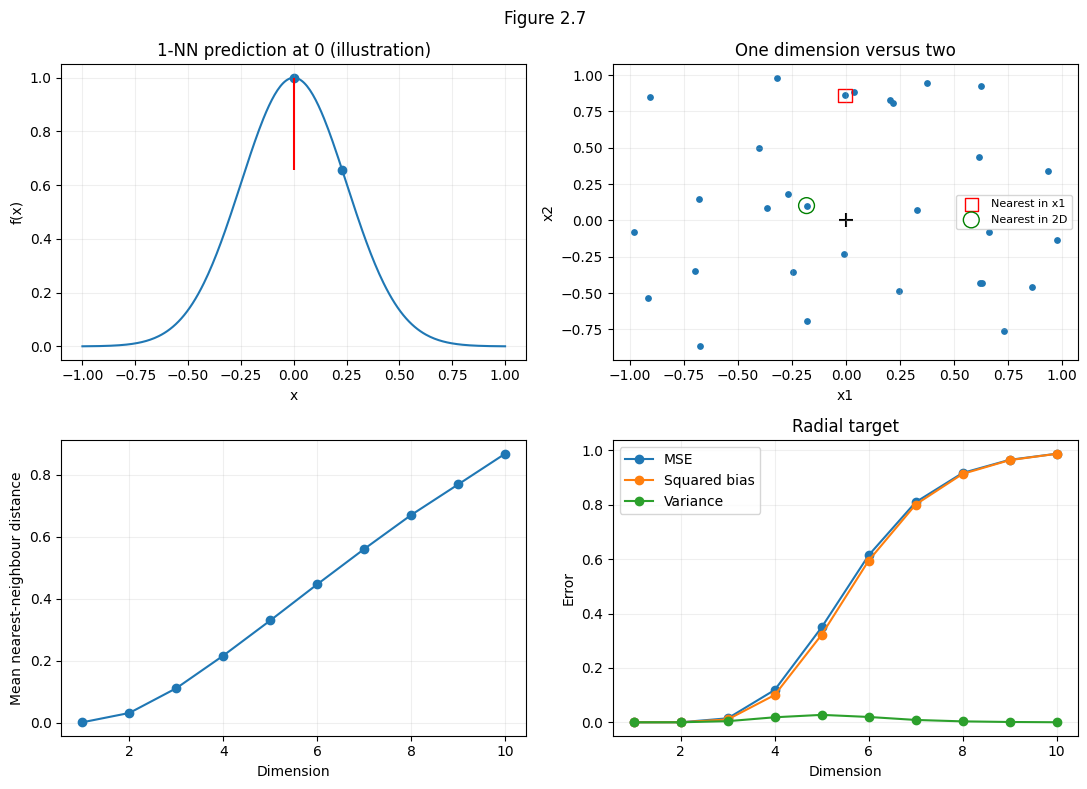

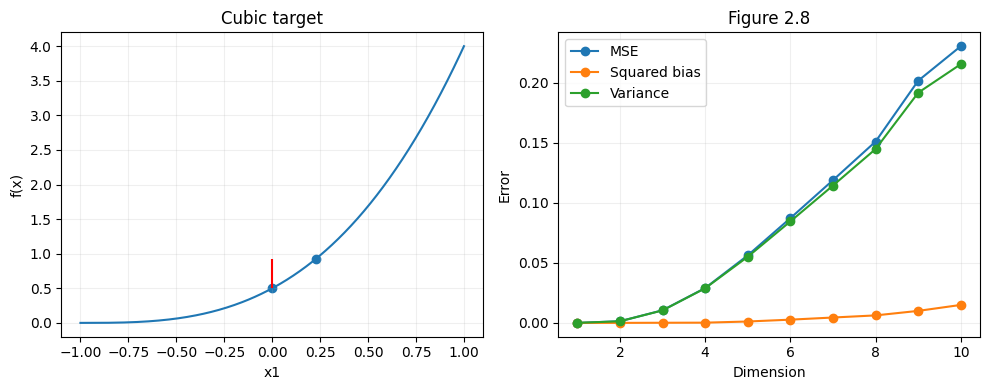

,Dimension,Mean distance,Radial MSE,Radial bias²,Cubic MSE,Cubic variance
0,1,0.0010,1.6081e-09,2.6699e-10,4.5962e-06,4.5948e-06
1,2,0.0311,1.8304e-04,9.4147e-05,1.3561e-03,1.3540e-03
2,3,0.1110,1.4687e-02,1.0548e-02,1.0509e-02,1.0404e-02
3,4,0.2161,1.1911e-01,1.0063e-01,2.9034e-02,2.8850e-02
4,5,0.3294,3.4984e-01,3.2251e-01,5.6272e-02,5.5118e-02
5,6,0.4460,6.1461e-01,5.9496e-01,8.7284e-02,8.4590e-02
6,7,0.5598,8.0980e-01,8.0115e-01,1.1898e-01,1.1450e-01
7,8,0.6695,9.1731e-01,9.1389e-01,1.5117e-01,1.4493e-01
8,9,0.7680,9.6559e-01,9.6444e-01,2.0187e-01,1.9186e-01
9,10,0.8670,9.8797e-01,9.8780e-01,2.3065e-01,2.1568e-01


In [11]:
dimensions = np.arange(1, 11)
repeats = 2000
# Rows correspond to dimensions; columns correspond to independently generated training sets.
nearest_distances = np.empty((10, repeats))
radial_predictions = np.empty((10, repeats))
cubic_predictions = np.empty((10, repeats))
rng = np.random.default_rng(31)
for index, dimension in enumerate(dimensions):
    for run in range(repeats):
        # Regenerate all 1000 training points on every repetition; the test point stays at zero.
        X = rng.uniform(-1, 1, (1000, dimension))
        squared_distance = np.sum(X ** 2, axis=1)
        # Use all coordinates to find the nearest neighbour, even for the target depending only on x1.
        nearest = squared_distance.argmin()
        nearest_distances[index, run] = np.sqrt(squared_distance[nearest])
        radial_predictions[index, run] = np.exp(-8 * squared_distance[nearest])
        cubic_predictions[index, run] = 0.5 * (X[nearest, 0] + 1) ** 3

# Average across training sets (axis=1); the true values at zero are 1 and 0.5.
radial_mse = np.mean((radial_predictions - 1) ** 2, axis=1)
radial_bias = (radial_predictions.mean(axis=1) - 1) ** 2
radial_variance = radial_predictions.var(axis=1)
cubic_mse = np.mean((cubic_predictions - 0.5) ** 2, axis=1)
cubic_bias = (cubic_predictions.mean(axis=1) - 0.5) ** 2
cubic_variance = cubic_predictions.var(axis=1)
# With no observation noise and ddof=0, the empirical bias-variance identity holds.
assert np.allclose(radial_mse, radial_bias + radial_variance)
assert np.allclose(cubic_mse, cubic_bias + cubic_variance)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
grid = np.linspace(-1, 1, 300)
# This fixed point illustrates prediction error; it is not used in the Monte Carlo estimates.
example_x = 0.23
axes[0, 0].plot(grid, np.exp(-8 * grid ** 2))
axes[0, 0].scatter([0, example_x], [1, np.exp(-8 * example_x ** 2)])
axes[0, 0].vlines(0, np.exp(-8 * example_x ** 2), 1, color='red')
axes[0, 0].set(title='1-NN prediction at 0 (illustration)', xlabel='x', ylabel='f(x)')
points = np.random.default_rng(32).uniform(-1, 1, (30, 2))
# Compare nearest points using x1 alone and using both coordinates.
nearest_1d = np.abs(points[:, 0]).argmin()
nearest_2d = np.sum(points ** 2, axis=1).argmin()
axes[0, 1].scatter(*points.T, s=15)
axes[0, 1].scatter(*points[nearest_1d], marker='s', s=90, facecolors='none', edgecolors='red', label='Nearest in x1')
axes[0, 1].scatter(*points[nearest_2d], marker='o', s=130, facecolors='none', edgecolors='green', label='Nearest in 2D')
axes[0, 1].scatter(0, 0, marker='+', color='black', s=100)
axes[0, 1].set(title='One dimension versus two', xlabel='x1', ylabel='x2')
axes[0, 1].legend(fontsize=8)
axes[1, 0].plot(dimensions, nearest_distances.mean(axis=1), 'o-')
axes[1, 0].set(xlabel='Dimension', ylabel='Mean nearest-neighbour distance')
for values, name in [(radial_mse, 'MSE'), (radial_bias, 'Squared bias'), (radial_variance, 'Variance')]:
    axes[1, 1].plot(dimensions, values, 'o-', label=name)
axes[1, 1].set(xlabel='Dimension', ylabel='Error', title='Radial target')
axes[1, 1].legend()
fig.suptitle('Figure 2.7')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(grid, 0.5 * (grid + 1) ** 3)
axes[0].scatter([0, example_x], [0.5, 0.5 * (example_x + 1) ** 3])
axes[0].vlines(0, 0.5, 0.5 * (example_x + 1) ** 3, color='red')
axes[0].set(title='Cubic target', xlabel='x1', ylabel='f(x)')
for values, name in [(cubic_mse, 'MSE'), (cubic_bias, 'Squared bias'), (cubic_variance, 'Variance')]:
    axes[1].plot(dimensions, values, 'o-', label=name)
axes[1].set(xlabel='Dimension', ylabel='Error', title='Figure 2.8')
axes[1].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame({'Dimension': dimensions, 'Mean distance': nearest_distances.mean(axis=1),
                      'Radial MSE': radial_mse, 'Radial bias²': radial_bias,
                      'Cubic MSE': cubic_mse, 'Cubic variance': cubic_variance}))

The mean nearest-neighbour distance increases from 0.001 in one dimension to 0.867 in ten dimensions. With the sample size fixed, the closest training point becomes less local.

For the radial target, moving away from zero lowers the function value below its true value of 1 at the origin. At p=10, MSE is 0.988 and consists almost entirely of squared bias. For the cubic target, only x1 determines the response, but all coordinates affect neighbour selection. Its MSE at p=10 is 0.231, of which 0.216 is variance. The same geometric change therefore produces different error components for the two targets.


**Question**

In Section 2.5 of the book "[The Elements of Statistical Learning: Data Mining, Inference, and Prediction](https://web.stanford.edu/~hastie/ElemStatLearn//printings/ESLII_print12_toc.pdf)", by T. Hastie, R. Tibshirani, and J. Friedman, there is a mention about the effects of the *curse of dimensionality*. Read the section and implement the code to reproduce and verify all the experiments shown in the Figures 2.6, 2.7, 2.8, and 2.9.

This part addresses Figure 2.9.

**Answer**

**Figure 2.9.** Use 500 training points and independent Gaussian observation noise with standard deviation 1. Compare 1-NN with OLS including an intercept, for a linear and a cubic target. Each point below averages 3000 training datasets. The expected error for a new noisy response is `1 + mean((prediction - f(0))**2)`: the added 1 is the independent test-noise variance. The plotted ratio is mean EPE of 1-NN divided by mean EPE of OLS.

This is the lecture's MSE decomposition into squared bias, prediction variance and Bayes error. The independent test-noise variance is 1 here; it is separate from the training noise already affecting the fitted model.


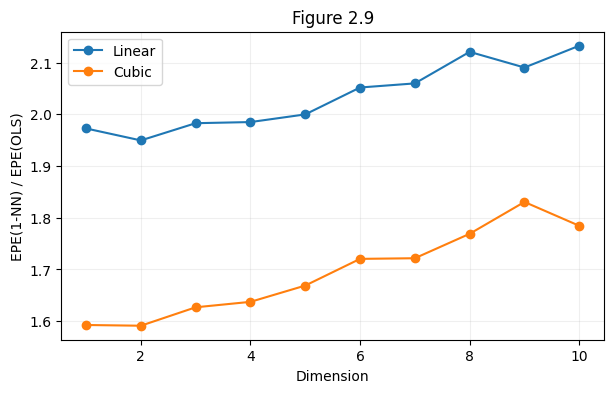

,Dimension,Target,1-NN EPE,OLS EPE,EPE ratio
0,1,Linear,1.9767,1.0020,1.9727
1,1,Cubic,1.9906,1.2499,1.5927
8,5,Linear,2.0041,1.0021,1.9999
9,5,Cubic,2.0891,1.2518,1.6689
18,10,Linear,2.1370,1.0020,2.1327
19,10,Cubic,2.2338,1.2518,1.7845


In [12]:
rng = np.random.default_rng(33)
epe_rows = []
for dimension in dimensions:
    # Two entries accumulate errors for the linear and cubic targets separately.
    nn_errors = np.zeros(2)
    ols_errors = np.zeros(2)
    target_at_zero = np.array([0., 0.5])
    for run in range(3000):
        X = rng.uniform(-1, 1, (500, dimension))
        # Columns are two separate response functions evaluated on the same inputs.
        signal = np.column_stack([X[:, 0], 0.5 * (X[:, 0] + 1) ** 3])
        y = signal + rng.normal(0, 1, (500, 2))
        nearest = np.sum(X ** 2, axis=1).argmin()
        # 1-NN keeps the selected observation noise; OLS fits both response columns separately.
        nn_prediction = y[nearest]
        ols_prediction = LinearRegression().fit(X, y).predict(np.zeros((1, dimension)))[0]
        nn_errors += (nn_prediction - target_at_zero) ** 2
        ols_errors += (ols_prediction - target_at_zero) ** 2
    # Add independent test-noise variance 1 to the error against the noise-free target.
    nn_epe = 1 + nn_errors / 3000
    ols_epe = 1 + ols_errors / 3000
    # Take the ratio of averaged EPEs, not the average of per-run error ratios.
    for index, name in enumerate(['Linear', 'Cubic']):
        epe_rows.append([dimension, name, nn_epe[index], ols_epe[index], nn_epe[index] / ols_epe[index]])

epe_results = pd.DataFrame(epe_rows, columns=['Dimension', 'Target', '1-NN EPE', 'OLS EPE', 'EPE ratio'])
for name in ['Linear', 'Cubic']:
    curve = epe_results[epe_results['Target'] == name]
    plt.plot(curve['Dimension'], curve['EPE ratio'], 'o-', label=name)
plt.xlabel('Dimension')
plt.ylabel('EPE(1-NN) / EPE(OLS)')
plt.title('Figure 2.9')
plt.legend()
plt.show()
display(epe_results[epe_results['Dimension'].isin([1, 5, 10])])

OLS uses all training points to estimate a few coefficients. It has low variance for the linear target, while 1-NN keeps the noise of one observation. This explains the ratio near two: it is 1.97 at p=1 and 2.13 at p=10 in these runs. OLS is biased for the cubic target, so its relative advantage is smaller; the corresponding ratios are 1.59 and 1.78. Monte Carlo fluctuations mean the simulated curves need not increase at every dimension.



## Exercise 4 - [15%]

**a)** The rule of thumb for **train/test split** ratio is to choose it to be quite larger than 1 (e.g. a 75%-25% train/test split). Validate empirically this choice:

* Choose a dataset for a classification task.
* Use a classification method that is suitable for the problem (i.e. performs reasonably well on the dataset).
* Try several train/test split ratio values (e.g. 0% to 100% with step 5%).
* Use plot(s) to display the performance of the method on the test set in each case.
* Justify in detail the observed behavior using arguments founded in the theory (see bias-variance trade off).
* What is (approx.) the best choice of ratio in your case?
* Now, using a train/validation/test split, optimize the hyperparameters of your model, and give the final trained model that you would deliver for practical use. 

**b)** *Cross-validation* splits the set of data in non-overlapping parts, then learns and tests the performance of a method independently in the different parts of the data, e.g. i) train-test set split, or ii) k-folded approach. 

Imagine that you have to apply (i) and (ii) for validating a regression method for time-series, a task which is also referred to as *time-series forecasting*. Note that in this case the element of time should be respected.

Describe a procedure, by giving a pseudocode, that would apply (i) and (ii).


### 4a. Training-set size and model selection

**Question**

**a)** The rule of thumb for **train/test split** ratio is to choose it to be quite larger than 1 (e.g. a 75%-25% train/test split). Validate empirically this choice:

* Choose a dataset for a classification task.
* Use a classification method that is suitable for the problem (i.e. performs reasonably well on the dataset).
* Try several train/test split ratio values (e.g. 0% to 100% with step 5%).
* Use plot(s) to display the performance of the method on the test set in each case.
* Justify in detail the observed behavior using arguments founded in the theory (see bias-variance trade off).
* What is (approx.) the best choice of ratio in your case?

**Answer**

Use scikit-learn's breast-cancer classification dataset and standardized logistic regression. Keeping this simple linear classifier fixed makes it easier to examine performance across training-set sizes. Standardization makes the regularization penalty more comparable across features with different scales; its means and standard deviations are fitted only on the current training portion. First reserve 20% as a final test set. The ratio experiment uses only the remaining 80%, with 30 random splits at each ratio. Thus the final test set is not used to select the ratio or the regularization parameter.

Ratios 0% and 100% cannot be evaluated: one leaves no training data, the other no test data. Test ratios from 5% to 95%. Error bars show the standard deviation across splits, not a confidence interval.

The standard deviation across splits combines changes in the fitted model and changes in the test sample. It does not separately estimate the bias and variance terms from the lecture.



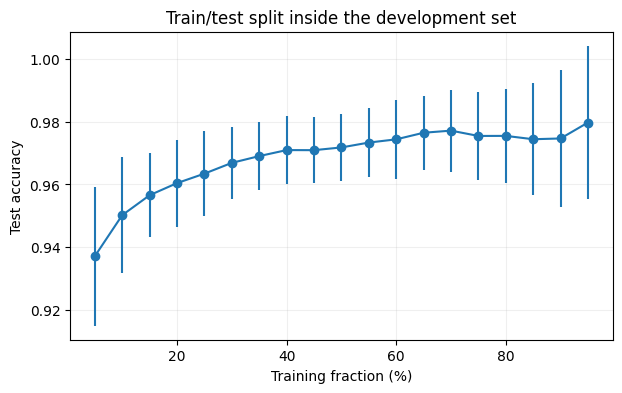

,Training %,Mean accuracy,SD
0,5,0.9372,0.0221
1,10,0.9502,0.0185
2,15,0.9566,0.0134
3,20,0.9604,0.0138
4,25,0.9635,0.0135
5,30,0.9669,0.0116
6,35,0.9690,0.0107
7,40,0.9709,0.0107
8,45,0.9709,0.0106
9,50,0.9718,0.0108


Largest observed mean: training fraction 95 %


In [13]:
data = load_breast_cancer()
# Reserve the final 20% before comparing ratios; it must not influence model selection.
development_X, final_test_X, development_y, final_test_y = train_test_split(
    data.data, data.target, test_size=0.2, random_state=40)
ratio_rows = []
# These percentages apply within the remaining development set, not the full dataset.
for percent in range(5, 100, 5):
    scores = []
    for seed in range(30):
        train_X, test_X, train_y, test_y = train_test_split(
            development_X, development_y, train_size=percent / 100, random_state=seed)
        # The pipeline fits scaling on training data only and reuses it for test predictions.
        model = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000))
        model.fit(train_X, train_y)
        scores.append(model.score(test_X, test_y))
    # Report variation across 30 random splits; SD is not a confidence interval.
    ratio_rows.append([percent, np.mean(scores), np.std(scores)])
ratio_results = pd.DataFrame(ratio_rows, columns=['Training %', 'Mean accuracy', 'SD'])
plt.errorbar(ratio_results['Training %'], ratio_results['Mean accuracy'], yerr=ratio_results['SD'], fmt='o-')
plt.xlabel('Training fraction (%)')
plt.ylabel('Test accuracy')
plt.title('Train/test split inside the development set')
plt.show()
display(ratio_results)
best_ratio = ratio_results.loc[ratio_results['Mean accuracy'].idxmax()]
print('Largest observed mean: training fraction', int(best_ratio['Training %']), '%')

From 65% to 95% training data, mean accuracy stays between 97.4% and 98.0%. The highest value is 97.97% at 95%, but each of those splits leaves only about 23 test points; 70% and 75% give 97.71% and 97.54%. The curve has plateaued after about 65%, and the gap at 95% is far smaller than the across-split standard deviation, so it does not show that 95% is better. This experiment therefore supports a broad 65–80% range rather than a unique 75/25 optimum.

Small training sets give more variable coefficient estimates. Increasing training size reduces this estimation variance but cannot remove model bias. Near the plateau, the benefit is limited, while the shrinking test set makes evaluation less stable: at 95% training, the across-split standard deviation is 2.44 percentage points, the largest of all ratios. A 75/25 development split keeps useful training data and a larger evaluation set than the extreme ratios.


**Question**

* Now, using a train/validation/test split, optimize the hyperparameters of your model, and give the final trained model that you would deliver for practical use.

**Answer**

For the final model, split the development set 75/25, giving about 60/20/20 overall for training, validation and testing. Choose C using validation accuracy only. Refit on training plus validation, then evaluate once on the untouched final test set. Standardization is fitted only with the corresponding training data.


In [14]:
# Split the 80% development set into training and validation: about 60/20/20 overall.
train_X, validation_X, train_y, validation_y = train_test_split(
    development_X, development_y, test_size=0.25, random_state=41)
validation_rows = []
# Smaller C means stronger regularization; compare candidates on validation data only.
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
    model.fit(train_X, train_y)
    validation_rows.append([C, model.score(validation_X, validation_y)])
validation_results = pd.DataFrame(validation_rows, columns=['C', 'Validation accuracy'])
display(validation_results)
# Choose C before consulting the final test set, then refit using all development data.
best_C = validation_results.loc[validation_results['Validation accuracy'].idxmax(), 'C']
final_model = make_pipeline(StandardScaler(), LogisticRegression(C=best_C, max_iter=2000))
final_model.fit(development_X, development_y)
final_accuracy = final_model.score(final_test_X, final_test_y)
print('Selected C:', best_C)
print('Final test accuracy:', round(final_accuracy, 4), '| test samples:', len(final_test_y))
# Save preprocessing together with the classifier and the expected feature/class order.
joblib.dump({'model': final_model, 'feature_names': data.feature_names, 'target_names': data.target_names},
            OUTPUT_DIR / 'Assignments1_model.joblib')

,C,Validation accuracy
0,0.001,0.8158
1,0.010,0.9386
2,0.100,0.9474
3,1.000,0.9561
4,10.000,0.9649
5,100.000,0.9474


Selected C: 10.0
Final test accuracy: 0.9649 | test samples: 114


['outputs/Assignments1_model.joblib']

C is the inverse regularization strength: smaller values constrain the coefficients more strongly. Validation accuracy is highest at `C=10` (96.49%), so this value is selected and the model is refitted on the full development set. The final model correctly classifies 110 of the 114 untouched test points (96.49%). This is the result on that particular test split, not a guarantee for every split. The saved `outputs/Assignments1_model.joblib` contains the fitted pipeline and the feature/class names.


### 4b. Time-series validation

**Question**

**b)** *Cross-validation* splits the set of data in non-overlapping parts, then learns and tests the performance of a method independently in the different parts of the data, e.g. i) train-test set split, or ii) k-folded approach. 

Imagine that you have to apply (i) and (ii) for validating a regression method for time-series, a task which is also referred to as *time-series forecasting*. Note that in this case the element of time should be respected.

Describe a procedure, by giving a pseudocode, that would apply (i) and (ii).

**Answer**

Training must precede validation in time. Random shuffling would let future observations help predict the past. Features and preprocessing must also use only information available at the forecast time.

```text
Holdout:
    sort observations by time
    choose a cutoff
    fit preprocessing and the model on observations before the cutoff
    forecast the next test block
    compare forecasts with the observed test values

Expanding-window k-fold validation:
    sort observations by time
    choose an initial training window and k later validation blocks
    for each validation block, from oldest to newest:
        use only earlier observations as the training set
        fit preprocessing and the model again
        forecast the validation block without using its future values
        store its prediction error
    average the validation errors, weighted by block size
```

For a multi-step forecast, do not use true intermediate future targets as lagged inputs. Add a gap where the target horizon would make training labels overlap the validation period. If parameters are selected with these folds, keep a still later block for final testing.


## Exercise 5 - [15%]

The purpose of this exercise is to apply classification for two data classes using a **simple linear model**. However, the particularity is that we are in the context of *stream processing* where data arrive sequentially in pairs of observations, containing one observation from each class, i.e. each time $t$ we observe $(x_t \in \text{class A}, x'_t \in \text{class B})$. As *we cannot store all the data* to apply batch processing, we need to develop a frugal online learning approach that would require as little as possible stored information at each time $t$ for a simple linear model $\text{model}_t$, which then would be updated based on the incoming $(x_t, x'_t)$'s. At any time $t$ the model $\text{model}_t$ should be able to classify unknown data.

**a)** Analyze in detail the requirements of this problem setting, and implement an approach to produce a linear model for all the data of the stream. Explain why it is correct and how much memory resources it would need to run.

**b)** To train your model consider $N = n+n$ data produced by two 2D Gaussian distributions ($n$ instances from each of them) that have (e.g.) same standard deviation and different mean values $\mu_1$ and $\mu_2$. Use a large $N$ (e.g. $500$) and show the performance of $\text{model}_t$ over the course of time (i.e. for $t=1,...,N$) using a test-set of $500 + 500$ datapoints generated from the same distributions. Compare in the same plot (e.g. it would appear as fixed horizontal line) against a linear classifier that is trained directly on the $N$ datapoints. Use a couple of $\mu_1$ and $\mu_2$ pairs to show an easy case and a more difficult one.


### 5a. Online nearest-centroid classifier

**Question**

The purpose of this exercise is to apply classification for two data classes using a **simple linear model**. However, the particularity is that we are in the context of *stream processing* where data arrive sequentially in pairs of observations, containing one observation from each class, i.e. each time $t$ we observe $(x_t \in \text{class A}, x'_t \in \text{class B})$. As *we cannot store all the data* to apply batch processing, we need to develop a frugal online learning approach that would require as little as possible stored information at each time $t$ for a simple linear model $\text{model}_t$, which then would be updated based on the incoming $(x_t, x'_t)$'s. At any time $t$ the model $\text{model}_t$ should be able to classify unknown data.

**a)** Analyze in detail the requirements of this problem setting, and implement an approach to produce a linear model for all the data of the stream. Explain why it is correct and how much memory resources it would need to run.

**Answer**

Following the exercise's class indices $\mu_1,\mu_2$, let $\mu_{1,t},\mu_{2,t}$ be their sample means after t pairs, corresponding to `mean_a` and `mean_b` in the code.

Keep one mean for each class and the number t of received pairs. Update the means by
$$\mu_{1,t}=\mu_{1,t-1}+\frac{x_t-\mu_{1,t-1}}{t},\qquad
\mu_{2,t}=\mu_{2,t-1}+\frac{x'_t-\mu_{2,t-1}}{t}.$$
For either class, $(t-1)\mu_{t-1}$ is the sum of the previously observed samples, so

$$\mu_t=\frac{(t-1)\mu_{t-1}+x_t}{t}
=\mu_{t-1}+\frac{x_t-\mu_{t-1}}{t}.$$

At $t=1$ this gives the first sample. Each update then preserves the sample mean, so the old mean and count replace the stored history.

For a new point z, the nearest-centroid rule chooses B when $\|z-\mu_{2,t}\|^2\leq\|z-\mu_{1,t}\|^2$. Expanding the squares cancels the common $z^Tz$ term and gives
$$z^T(\mu_{2,t}-\mu_{1,t})+\frac{\|\mu_{1,t}\|^2-\|\mu_{2,t}\|^2}{2}\geq0.$$
The resulting score contains only first-order terms in z, so the boundary is linear. The stored state is two d-dimensional means and one counter: $O(d)$ memory, with $O(d)$ work per pair. No past observations are needed.

For equal class priors and equal isotropic Gaussian covariances, the population rule is Bayes-optimal. With estimated means it is a plug-in classifier, not a claim of optimality for arbitrary streams or unequal covariances. Both classes must be observed before prediction; here this holds after the first pair.


### 5b. Experiment

**Question**

**b)** To train your model consider $N = n+n$ data produced by two 2D Gaussian distributions ($n$ instances from each of them) that have (e.g.) same standard deviation and different mean values $\mu_1$ and $\mu_2$. Use a large $N$ (e.g. $500$) and show the performance of $\text{model}_t$ over the course of time (i.e. for $t=1,...,N$) using a test-set of $500 + 500$ datapoints generated from the same distributions. Compare in the same plot (e.g. it would appear as fixed horizontal line) against a linear classifier that is trained directly on the $N$ datapoints. Use a couple of $\mu_1$ and $\mu_2$ pairs to show an easy case and a more difficult one.

**Answer**

Take N=500 total training points, hence 250 arrival pairs, and an independent test set of 500 points per class. This resolves the question's inconsistent use of N for both points and pair arrivals. Use standard deviation 1, with mean separations 4 (easy) and 1 (hard). The batch baseline is the same nearest-centroid rule fitted on all 500 points. Arrays are retained here only to simulate the stream and compute that comparison.


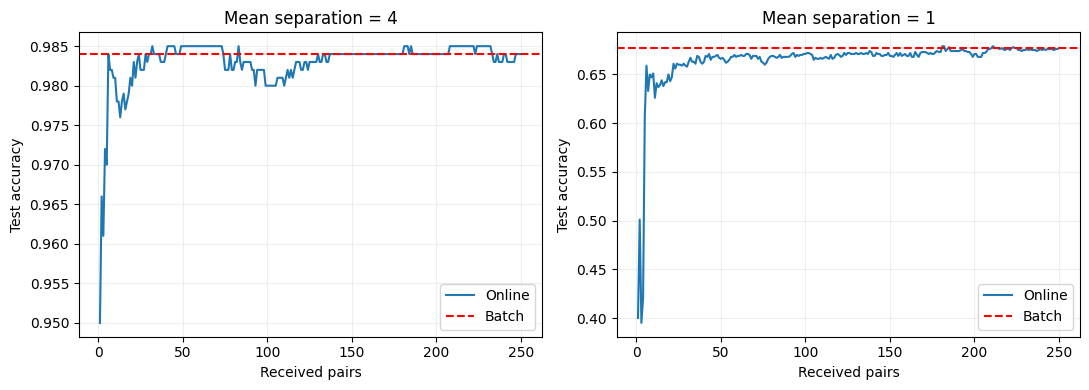

,Separation,First pair,Last pair,Batch,Population Bayes accuracy
0,4,0.95,0.984,0.984,0.9772
1,1,0.40,0.677,0.677,0.6915


In [15]:
def update_means(mean_a, mean_b, point_a, point_b, t):
    # t counts received pairs, hence also the number of observations seen in each class.
    mean_a = mean_a + (point_a - mean_a) / t
    mean_b = mean_b + (point_b - mean_b) / t
    return mean_a, mean_b


def centroid_predict(X, mean_a, mean_b):
    # Expanding the two squared distances gives this linear decision score.
    weights = mean_b - mean_a
    intercept = (mean_a @ mean_a - mean_b @ mean_b) / 2
    return (X @ weights + intercept >= 0).astype(int)


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
stream_rows = []
for ax, separation in zip(axes, [4, 1]):
    rng = np.random.default_rng(50)
    mu_a = np.array([-separation / 2, 0])
    mu_b = np.array([separation / 2, 0])
    # Store arrays only to simulate arrivals and compute the batch reference.
    stream_a = rng.normal(mu_a, 1, (250, 2))
    stream_b = rng.normal(mu_b, 1, (250, 2))
    # Generate an independent test set; these observations never update the means.
    test_X = np.vstack([rng.normal(mu_a, 1, (500, 2)), rng.normal(mu_b, 1, (500, 2))])
    test_y = np.repeat([0, 1], 500)
    mean_a = np.zeros(2)
    mean_b = np.zeros(2)
    scores = []
    # After each pair, evaluate the current model on the same fixed test set.
    for t, (point_a, point_b) in enumerate(zip(stream_a, stream_b), start=1):
        mean_a, mean_b = update_means(mean_a, mean_b, point_a, point_b, t)
        scores.append(accuracy_score(test_y, centroid_predict(test_X, mean_a, mean_b)))
    batch_a = stream_a.mean(axis=0)
    batch_b = stream_b.mean(axis=0)
    batch_score = accuracy_score(test_y, centroid_predict(test_X, batch_a, batch_b))
    # At the end, incremental means must agree with batch means on the same observations.
    assert np.allclose(mean_a, batch_a) and np.allclose(mean_b, batch_b)
    assert np.array_equal(centroid_predict(test_X, mean_a, mean_b), centroid_predict(test_X, batch_a, batch_b))
    ax.plot(np.arange(1, 251), scores, label='Online')
    ax.axhline(batch_score, color='red', linestyle='--', label='Batch')
    ax.set(title='Mean separation = ' + str(separation), xlabel='Received pairs', ylabel='Test accuracy')
    ax.legend()
    # Phi(separation / 2) is the population Bayes accuracy here: equal priors and unit isotropic variance.
    stream_rows.append([separation, scores[0], scores[-1], batch_score, norm.cdf(separation / 2)])
plt.tight_layout()
plt.show()
display(pd.DataFrame(stream_rows, columns=['Separation', 'First pair', 'Last pair', 'Batch', 'Population Bayes accuracy']))

The final online and batch predictions agree because their class means agree. Test accuracy is 98.4% in the easy case and 67.7% in the hard case. Early predictions fluctuate more. Learning more points estimates the means better, but it cannot remove the overlap between the two Gaussian classes. Consequently the hard case remains less accurate. Test accuracy need not improve after every update.

The Bayes accuracy column uses the midpoint boundary for equal-prior Gaussians with equal isotropic covariance. Finite-test accuracy can exceed this population reference through sampling variation.



## Exercise 6 - [15%]

Relying on the central hypothesis that a learning problem should enjoy regularity along the domain of the data (see [Lab 1](http://kalogeratos.com/MyCourses/DML-M2HPC/Lab1.ipynb)), we would like to define a heuristic data-driven measure to evaluate a given model.

More specifically, consider a classification problem and define a regularity measure based on the nearest neighbors principle that can assess how regular the decisions of a given classifier are. Explain the logic of your proposition. Let's call this function **Regularity(X, Y, +any needed parameters)**.

**Recipe for testing**

In this exercise you have to generate data from a mixture of 2 Gaussian distributions, and then measure the effect of your Regularity measure and the standard Accuracy with regards to the following factors:

* the size of the dataset; try generating classes of same standard deviation $\sigma = 2$ and equal size, where each of them will have $n_i\in\{50, 100, 200, 500\}$ objects;
* the dimensionality $d$ of the data; try $d\in\{1,5 ,10, 20, 50, 100\}$;
* the overlap of the classes $\delta$ in the feature space, i.e. the distance between the classes; try $\delta\in\{\sigma, 2\sigma, 3\sigma, 4\sigma\}$;
* the input parameter $k$ which indirectly adjusts how far from an object the classifier will seek for 'advice' from other objects in order to classify it; try $k\in\{1,...\,,10\}$.

**Sample pseudocode:**  

for each tuple <$n$, $d$, $\delta$, $k$>
   * generate data  
   * compute average quality over $10$ runs of the following  
       * train a $k$NN classifier and a decision tree (choose nicely the depth)   
       * test the classifiers using Accuracy and Regularity  

end for

The evaluation should be performed with and without 10-fold CV (inside the train/test nested part). Use at least the suggested value range for each parameter, but you can extend it if this way you capture some interesting behavior. 

**Questions:** 
- What is the main difference between a $k$NN and a radius-NN classifier? In which case(s) one is better to the other? How would we have to adapt the above discussion if radius-NN classifier is used instead of the standard $k$NN?
- What would change if we were interested in measuring the Regularity in the context of a regression problem?


### 6. Local agreement as regularity

**Question**

Relying on the central hypothesis that a learning problem should enjoy regularity along the domain of the data (see [Lab 1](http://kalogeratos.com/MyCourses/DML-M2HPC/Lab1.ipynb)), we would like to define a heuristic data-driven measure to evaluate a given model.

More specifically, consider a classification problem and define a regularity measure based on the nearest neighbors principle that can assess how regular the decisions of a given classifier are. Explain the logic of your proposition. Let's call this function **Regularity(X, Y, +any needed parameters)**.

**Answer**

For a point predicted as A, neighbour predictions A, A, B, A, B give local agreement $3/5$. The proposed measure averages this fraction over evaluation points.

The exercise asks for a proposed Regularity measure. For this solution, let m be the number of evaluation points, $\hat y_i$ the predicted label at $x_i$, and $N_q(i)$ its q nearest other evaluation points. This evaluation parameter q is separate from the classifier's k. Define
$$R(X,\hat y)=\frac{1}{mq}\sum_{i=1}^m\sum_{j\in N_q(i)}\mathbf{1}[\hat y_i=\hat y_j].$$
It is between 0 and 1. A high value means nearby points receive similar decisions. It does not use the true labels, while Accuracy does. A constant classifier has R=1 even when its accuracy is poor, so the two measures must be reported together.

Use q=5 throughout to keep this neighbourhood parameter separate from the classifier's k. Both classes have standard deviation 2. Their means are $(0,\ldots,0)$ and $(\delta,0,\ldots,0)$, so their Euclidean separation stays delta as dimension grows. Extra dimensions add noise, not extra signal.


In [16]:
def Regularity(X, Y, q=5, neighbours=None):
    # Y contains predicted labels, not ground truth; optional neighbours avoid repeated searches.
    if neighbours is None:
        count = min(q, len(X) - 1)
        search = NearestNeighbors(n_neighbors=count).fit(X)
        neighbours = search.kneighbors(return_distance=False)  # Excludes each point itself.
    # Broadcast each label against its neighbours, then average all agreement indicators.
    return np.mean(Y[:, None] == Y[neighbours])


def evaluate_classifiers(train_X, train_y, test_X, test_y):
    # One neighbour search serves all ten k values.
    search = NearestNeighbors(n_neighbors=10).fit(train_X)
    indices = search.kneighbors(test_X, return_distance=False)
    neighbour_labels = train_y[indices]
    # Regularity uses neighbours among evaluation points, independently of training neighbours.
    local_search = NearestNeighbors(n_neighbors=min(5, len(test_X) - 1)).fit(test_X)
    local_neighbours = local_search.kneighbors(return_distance=False)
    # The fixed tree does not depend on k, so fit it once and repeat its score across k.
    tree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=0)
    tree.fit(train_X, train_y)
    tree_prediction = tree.predict(test_X)
    scores = np.empty((2, 10, 2))  # Model, k, metric.
    for k in range(1, 11):
        # Uniform binary kNN; tied votes go to class 0, as in sklearn.
        prediction = (neighbour_labels[:, :k].sum(axis=1) > k / 2).astype(int)
        scores[0, k - 1] = [accuracy_score(test_y, prediction),
                            Regularity(test_X, prediction, neighbours=local_neighbours)]
        scores[1, k - 1] = [accuracy_score(test_y, tree_prediction),
                            Regularity(test_X, tree_prediction, neighbours=local_neighbours)]
    return scores


# Check the reused-neighbour vote against sklearn before the full experiment.
check_rng = np.random.default_rng(60)
check_X = check_rng.normal(size=(80, 5))
check_y = check_rng.integers(0, 2, 80)
check_test = check_rng.normal(size=(20, 5))
check_indices = NearestNeighbors(n_neighbors=10).fit(check_X).kneighbors(check_test, return_distance=False)
for k in range(1, 11):
    prediction = (check_y[check_indices[:, :k]].sum(axis=1) > k / 2).astype(int)
    reference = KNeighborsClassifier(n_neighbors=k).fit(check_X, check_y).predict(check_test)
    assert np.array_equal(prediction, reference)
# A constant classifier must score 1, illustrating why regularity alone is insufficient.
assert Regularity(check_test, np.zeros(20, dtype=int)) == 1
print('Neighbour voting and constant-classifier check passed.')

Neighbour voting and constant-classifier check passed.


**Question**

**Recipe for testing**

In this exercise you have to generate data from a mixture of 2 Gaussian distributions, and then measure the effect of your Regularity measure and the standard Accuracy with regards to the following factors:

* the size of the dataset; try generating classes of same standard deviation $\sigma = 2$ and equal size, where each of them will have $n_i\in\{50, 100, 200, 500\}$ objects;
* the dimensionality $d$ of the data; try $d\in\{1,5 ,10, 20, 50, 100\}$;
* the overlap of the classes $\delta$ in the feature space, i.e. the distance between the classes; try $\delta\in\{\sigma, 2\sigma, 3\sigma, 4\sigma\}$;
* the input parameter $k$ which indirectly adjusts how far from an object the classifier will seek for 'advice' from other objects in order to classify it; try $k\in\{1,...\,,10\}$.

**Sample pseudocode:**  

for each tuple <$n$, $d$, $\delta$, $k$>
   * generate data  
   * compute average quality over $10$ runs of the following  
       * train a $k$NN classifier and a decision tree (choose nicely the depth)   
       * test the classifiers using Accuracy and Regularity  

end for

The evaluation should be performed with and without 10-fold CV (inside the train/test nested part). Use at least the suggested value range for each parameter, but you can extend it if this way you capture some interesting behavior.

**Answer**

Generate 10 datasets for each `(n, d, delta)` setting, giving 960 datasets in total. All ten k values share the same data and splits. Each dataset is randomly split into 80% development data and 20% outer test data. For example, n=50 gives 100 points: 80 for training and internal selection, and 20 for the outer test. “Holdout” evaluates on those 20 points. “Inner CV” uses only these 80 development points, fitting on 72 and validating on 8 in each of ten folds before averaging. The outer test set does not participate in internal selection. The tree uses depth 5 and at least 5 points per leaf, fixed before testing. For fixed tree settings, k has no effect on the tree, so its score is repeated across k for comparison.

Finally, select k using only inner-CV Accuracy and report its outer-test Accuracy and Regularity separately. The folds here are equally sized, so comparing total correct predictions is equivalent to comparing mean accuracy. The code accumulates integer counts to avoid roundoff affecting ties; equal totals select the smaller k. Inner-fold and outer-test Regularity use different-sized point sets, so their values are not directly interchangeable: their geometric neighbourhoods can differ.


In [17]:
regularity_rows = []
selected_rows = []
experiment_start = time.perf_counter()
# n is the number per class; each dataset contains 2*n observations.
for n in [50, 100, 200, 500]:
    for dimension in [1, 5, 10, 20, 50, 100]:
        for separation in [2, 4, 6, 8]:
            for run in range(10):
                seed = 100000 * n + 1000 * dimension + 10 * separation + run
                rng = np.random.default_rng(seed)
                class_a = rng.normal(0, 2, (n, dimension))
                class_b = rng.normal(0, 2, (n, dimension))
                # Only the first coordinate separates the classes; additional dimensions add noise.
                class_b[:, 0] += separation
                X = np.vstack([class_a, class_b])
                y = np.repeat([0, 1], n)
                # Keep an outer test set separate from the ten inner validation folds.
                train_X, test_X, train_y, test_y = train_test_split(
                    X, y, test_size=0.2, random_state=run)
                # All k values share this data split; compute their outer scores for later reporting.
                holdout_scores = evaluate_classifiers(train_X, train_y, test_X, test_y)
                # Run cross-validation inside the training portion; refit each model on each fold.
                folds = KFold(n_splits=10, shuffle=True, random_state=run)
                cv_scores = np.zeros((2, 10, 2))
                correct_counts = np.zeros(10, dtype=int)
                for fit_indices, validation_indices in folds.split(train_X):
                    fold_scores = evaluate_classifiers(
                        train_X[fit_indices], train_y[fit_indices],
                        train_X[validation_indices], train_y[validation_indices])
                    # Average ten equally sized validation folds for each model, k and metric.
                    cv_scores += fold_scores / 10
                    # Recover integer correct counts before adding folds to avoid roundoff ties.
                    correct_counts += np.rint(
                        fold_scores[0, :, 0] * len(validation_indices)).astype(int)
                for mode, scores in [('Holdout', holdout_scores), ('Inner CV', cv_scores)]:
                    for model_index, name in enumerate(['kNN', 'Tree']):
                        for k in range(1, 11):
                            accuracy, regularity = scores[model_index, k - 1]
                            regularity_rows.append([n, dimension, separation, k, run, mode, name,
                                                    accuracy, regularity])
                # Select using inner validation counts only; the already computed outer scores do not choose k.
                chosen_k = correct_counts.argmax() + 1  # Equal totals choose the smaller k.
                accuracy, regularity = holdout_scores[0, chosen_k - 1]
                selected_rows.append([n, dimension, separation, run, chosen_k, accuracy, regularity])
    print('Finished n =', n, 'per class')

regularity_results = pd.DataFrame(regularity_rows, columns=[
    'n', 'd', 'delta', 'k', 'Run', 'Evaluation', 'Model', 'Accuracy', 'Regularity'])
selected_results = pd.DataFrame(selected_rows, columns=[
    'n', 'd', 'delta', 'Run', 'Selected k', 'Outer accuracy', 'Outer regularity'])
# Save the full comparison grid and selected-k outer results as separate tables.
regularity_results.to_csv(OUTPUT_DIR / 'Assignments1_ex6_results.csv', index=False)
selected_results.to_csv(OUTPUT_DIR / 'Assignments1_ex6_selected.csv', index=False)
print('Result rows:', len(regularity_results), '| elapsed seconds:', round(time.perf_counter() - experiment_start, 1))
display(regularity_results.groupby(['Evaluation', 'Model'])[['Accuracy', 'Regularity']].mean())
display(selected_results.groupby('d')[['Selected k', 'Outer accuracy', 'Outer regularity']].mean())

Finished n = 50 per class


Finished n = 100 per class


Finished n = 200 per class


Finished n = 500 per class
Result rows: 38400 | elapsed seconds: 71.1


Accuracy  Regularity
Evaluation Model                      
Holdout    Tree     0.8205      0.7502
           kNN      0.7854      0.7358
Inner CV   Tree     0.8212      0.6919
           kNN      0.7840      0.6832

,Selected k,Outer accuracy,Outer regularity
d,,,
1,6.2375,0.8372,0.9096
5,6.9062,0.8345,0.8189
10,7.2875,0.8111,0.7569
20,7.5000,0.8063,0.7101
50,7.5375,0.7668,0.6520
100,7.8500,0.7366,0.6107


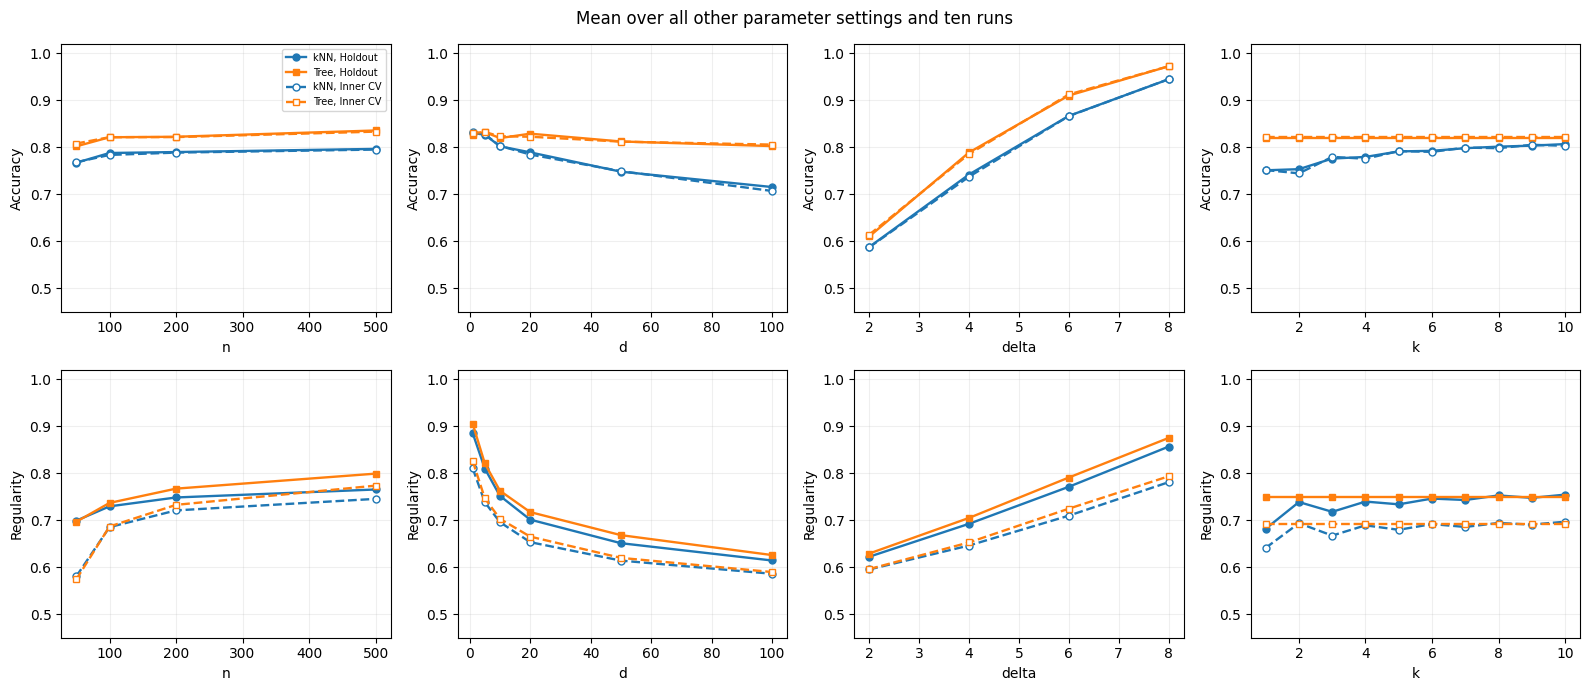

In [18]:
# Columns vary n, d, separation and k; rows show accuracy and regularity.
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for column, parameter in enumerate(['n', 'd', 'delta', 'k']):
    for row, metric in enumerate(['Accuracy', 'Regularity']):
        ax = axes[row, column]
        for evaluation, style in [('Holdout', '-'), ('Inner CV', '--')]:
            for name, colour in [('kNN', 'tab:blue'), ('Tree', 'tab:orange')]:
                selected = regularity_results[(regularity_results['Evaluation'] == evaluation) &
                                               (regularity_results['Model'] == name)]
                # Average over all other parameter values and runs; each curve combines different tasks.
                curve = selected.groupby(parameter)[metric].mean()
                ax.plot(curve.index, curve.values, style, marker='o' if name == 'kNN' else 's',
                        markerfacecolor='white' if evaluation == 'Inner CV' else colour,
                        markersize=5, linewidth=1.7, color=colour,
                        label=name + ', ' + evaluation)
        ax.set(xlabel=parameter, ylabel=metric, ylim=(0.45, 1.02))
axes[0, 0].legend(fontsize=7)
fig.suptitle('Mean over all other parameter settings and ten runs')
plt.tight_layout()
plt.show()

Averaged over the other settings, holdout kNN accuracy drops from 83.06% at d=1 to 71.55% at d=100; tree accuracy drops from 82.65% to 80.27%. Added dimensions carry no class information here, but still enter the kNN distance. The tree can use the informative first coordinate, which helps explain its smaller decline. Across the full grid, mean accuracy is 78.54% for kNN and 82.05% for the tree.

Increasing k from 1 to 10 raises average kNN accuracy from 75.11% to 80.69% and regularity from 0.682 to 0.755. In these averages, using more neighbours improves both prediction and local agreement. Larger class separation makes classification easier, and more samples generally help. These are averages across settings; larger k can still blur a boundary, and even k uses class-0 tie breaking in this implementation.

Inner-CV regularity is lower partly because validation folds are smaller: five neighbours span a different spatial range. For example, in an eight-point fold where one class has four points, even perfect predictions leave each of those points with at least two other-class neighbours among its five. Thus regularity must be read alongside accuracy and the evaluation-set size. The CV training sets also overlap, so folds are not independent repeated experiments.


**Question**

- What is the main difference between a $k$NN and a radius-NN classifier? In which case(s) one is better to the other? How would we have to adapt the above discussion if radius-NN classifier is used instead of the standard $k$NN?

**Answer**

**kNN versus radius-NN.** kNN fixes the number of neighbours and allows their distance to vary. Radius-NN fixes a distance and allows the number of neighbours to vary. kNN is convenient when density varies and a prediction is always needed. Radius-NN is useful when a meaningful physical distance is known, but sparse regions can have no neighbours. To repeat this experiment with radius-NN, sweep a radius grid instead of k and report the fraction of points receiving a prediction. An explicit fallback or abstention rule is needed for empty neighbourhoods. A fixed radius becomes particularly sparse in high dimension.


**Question**

- What would change if we were interested in measuring the Regularity in the context of a regression problem?

**Answer**

**Regression.** Replace label agreement with a penalty for nearby predicted values being different. For example,
$$R_{\rm reg}=\frac{1}{1+\frac{1}{mq s_y^2}\sum_i\sum_{j\in N_q(i)}(\hat y_i-\hat y_j)^2},$$
where $s_y^2>0$ is a fixed target scale estimated from training data. A constant prediction still gives 1, so also report test MSE. A genuinely steep regression function can have lower local agreement without being wrong.


## References

1. Argyris Kalogeratos, [Assignment 1](http://kalogeratos.com/files/MyCourses/DML-M2HPC/Assignments1.ipynb) and [Lab 1](http://kalogeratos.com/MyCourses/DML-M2HPC/Lab1.ipynb). The original question text, regression-data generation, logistic regression pipeline, and cross-validation protocols come from these materials.
2. Hastie, Tibshirani and Friedman, [The Elements of Statistical Learning](https://web.stanford.edu/~hastie/ElemStatLearn//printings/ESLII_print12_toc.pdf), Section 2.5 (Figures 2.6–2.9), Section 7.10 (Cross-Validation), Section 13.3 ($k$-Nearest-Neighbor Classifiers), and Section 14.3.6 ($K$-Means).
3. scikit-learn documentation: [RANSACRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RANSACRegressor.html), [OneClassSVM](https://scikit-learn.org/stable/modules/generated/sklearn.svm.OneClassSVM.html), [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html), and [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).
4. Kalogeratos et al., [Document clustering using synthetic cluster prototypes](https://kalogeratos.com/files/MyPapers/Document-clustering-using-synthetic-cluster-prototypes-DKE2011-recompiled.pdf), 2011, Algorithm 2. This assignment uses its simplified growing-neighbourhood idea with Euclidean distance, without document feature selection.
5. Course lectures: [01_intro](../../Lectures/01_intro.md) (prediction error decomposition, bias–variance trade-off, Bayes optimal classifier, and local regularity hypothesis), [02_LM](../../Lectures/02_LM_zh.md) (cross-validation and pipeline standardization), [03_LMC](../../Lectures/03_LMC_zh.md) (Gaussian class-conditional models, LDA, and nearest-centroid linear discriminant), and [05_NLM](../../Lectures/05_NLM_zh.md) ($k$NN and decision tree local methods).


## Use of LLMs

**Tool and scope.**

I used OpenAI ChatGPT while preparing Exercises 1–6 to clarify theoretical concepts, discuss methodological and implementation choices, check my understanding of mathematical reasoning, debug Python code, generate plotting code, and assist with English editing and Chinese translation.

**Conceptual and methodological assistance.**

My discussions with ChatGPT covered the interpretation of methods, parameter choices, and the limitations of alternative approaches across Exercises 1–6 (for example, how the RANSAC residual threshold in `ransac_line` determines inliers in Exercise 1, the estimation-variance versus evaluation-variance trade-off in Exercise 4, the equivalence between incremental class means and the batch nearest-centroid linear classifier in Exercise 5, and the distinction between neighborhood decision smoothness and classification accuracy in Exercise 6). These explanations informed my implementation and experimental choices.

**Implementation and debugging.**

I wrote the main computational implementations for RANSAC regression and point voting, robust representative estimation and clustering (Exercises 1–2), the curse-of-dimensionality experiments (Exercise 3), the train/validation/test split and time-series validation procedures (Exercise 4), the frugal online linear classifier (Exercise 5), and the local regularity evaluation across the parameter grid (Exercise 6).

ChatGPT helped identify Python errors, explain their causes, and suggest corrections. I incorporated these suggestions into my code, so the final implementations include AI-assisted debugging changes.

**Visualization.**

ChatGPT generated Python/Matplotlib plotting code for comparing regression models, displaying clustering results, presenting the curse-of-dimensionality experiments, and plotting train/test split curves, online learning trajectories, and regularity comparisons. I integrated these snippets with the datasets, fitted models, and numerical results computed in the notebook. The figure-generation code therefore includes AI-generated material.

**Editing and responsibility.**

ChatGPT helped revise English phrasing, clarify written explanations, and translate material into Chinese. It also helped me format mathematical expressions in LaTeX. I incorporated these language suggestions into the report and preparation materials.

I take responsibility for the final code, figures, and reported results, including verifying them, explaining the implemented methods, and interpreting the findings.
